# Cancer meta-programmes

## Imports


In [1]:
from __future__ import annotations
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path
from cap.figures import (
    configure_figure_style,
    save_figure,
    save_umap_figure,
)
from cap.paths import get_paths
from cap.provenance import (
    sha256_file,
    validate_frozen_inputs,
    write_run_provenance,
)
import argparse
import hashlib


In [2]:
import itertools
import json
import marshal
import os
import platform


In [3]:
import re
import sys
import types
from anndata.io import read_elem
from matplotlib import colormaps


In [4]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import to_hex
from matplotlib.lines import Line2D
from scipy import __version__ as scipy_version
from scipy import sparse


In [5]:
from scipy import stats
from scipy.stats import kruskal, rankdata
from statsmodels.stats.multitest import multipletests
from tqdm.auto import tqdm
import anndata as ad


In [6]:
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc


In [7]:
import scipy.sparse as sp
import seaborn as sns
import session_info


## Paths


In [8]:
# CAP_DATA_ROOT and CAP_RUN_ID are read from the environment or repository .env.
paths = get_paths()
paths.validate_base_inputs()
validate_frozen_inputs(paths)
project = paths.root


In [9]:
analysis_dir = paths.run_root


In [10]:
import logging
logging.getLogger("fontTools.subset").setLevel(logging.WARNING)


In [11]:
data_dir = paths.data_root


In [12]:
run_dir = paths.ensure_stage("03b_meta_programmes")


In [13]:
integration_dir = paths.stage_dir("03a_epithelial_integration")
paths.require_dir(integration_dir, "03a_epithelial_integration stage")


WindowsPath('D:/IdeaProjects/CAP_Submission/CAP_Data/runs/preprocessing_test_003/03a_epithelial_integration')

In [14]:
adata_file = integration_dir / "h5ad" / "epithelial_tumour_scvi.h5ad"


In [15]:
reference_dir = paths.frozen_dir


In [16]:
notebook_dir = paths.root / "notebooks"


The 41 published meta-programmes are projected onto tumour-derived epithelial cells.
The primary analysis uses an adapted matched-null scoring framework rather than
the original 3CA assignment algorithm. Programme calls keep
low-activity and ambiguous cells explicit. Donors, not cells, are the unit for
condition comparisons. Cluster summaries describe relative enrichment and are
not propagated as cell identities.

In [17]:
random_seed = 0


In [18]:
np.random.seed(random_seed)


In [19]:
sc.settings.verbosity = 2


In [20]:
configure_figure_style()


In [21]:
save_dir = run_dir / "h5ad"


In [22]:
paths.require_file(adata_file, "03a epithelial integration H5AD")
if any(run_dir.iterdir()):
    raise FileExistsError(
        f"{run_dir} is not empty. Set a fresh CAP_RUN_ID for a new immutable run."
    )


In [23]:
df_dir = run_dir / "tables"


In [24]:
fig_dir = run_dir / "figures"


In [25]:
# Figure typography and export settings are configured centrally by cap.figures.


In [26]:
for directory in (save_dir, df_dir, fig_dir):
    directory.mkdir(parents=True, exist_ok=True)

write_run_provenance(paths, run_dir)

input_checksums = {
    "03a_epithelial_integration/h5ad/epithelial_tumour_scvi.h5ad": sha256_file(adata_file),
    "gene_policy.json": sha256_file(paths.frozen_dir / "gene_policy.json"),
    "cancer_meta_programme_signatures.xlsx": sha256_file(
        paths.frozen_dir / "cancer_meta_programme_signatures.xlsx"
    ),
    "mammary_lineage_signatures.json": sha256_file(
        paths.frozen_dir / "mammary_lineage_signatures.json"
    ),
    "frozen_inputs.json": sha256_file(paths.manifest_dir / "frozen_inputs.json"),
}
(run_dir / "input_checksums.json").write_text(
    json.dumps(input_checksums, indent=2) + "\n",
    encoding="utf-8",
)


534

In [27]:
policy_file = reference_dir / "gene_policy.json"


In [28]:
policy_sha256 = "c4213d53e2d3209312e7781c73ed20f660e0f256042956742693c0e0375926a6"


In [29]:
def load_gene_policy(path=policy_file):
    path = Path(path)
    payload = path.read_bytes()
    digest = hashlib.sha256(payload).hexdigest()
    if digest != policy_sha256:
        raise ValueError(
            "Gene-policy checksum differs from the reviewed source snapshot"
        )
    policy = json.loads(payload)
    policy["sha256"] = digest
    return policy


In [30]:
gene_policy = load_gene_policy()


In [31]:
meta_programme_file = reference_dir / "cancer_meta_programme_signatures.xlsx"


In [32]:
signature_source = "Gavish et al. 2023, Supplementary Table 2, Cancer MPs"


In [33]:
signature_source_url = "https://doi.org/10.1038/s41586-023-06130-4"


In [34]:
three_ca_method_url = "https://github.com/tiroshlab/3ca/blob/main/ITH_hallmarks/MPs_distribution/MP_distribution.R"


In [35]:
three_ca_scoring_url = "https://github.com/jlaffy/scalop/blob/master/R/sigScores.R"


In [36]:
signature_sha256 = "a980e87edf6b216f591e29452f85d16bdc87b510c9b5989f524096e1862ac377"


In [37]:
sample_key = "sample"


In [38]:
donor_key = "patient"


In [39]:
condition_key = "condition"


In [40]:
cluster_key = "epi_leiden"


In [41]:
expression_layer = "lognorm"


In [42]:
min_cells_per_sample = 100


In [43]:
min_signature_coverage = 0.5


In [44]:
n_expression_bins = 25


In [45]:
n_controls_per_gene = 5


In [46]:
n_null_signatures = 10000


In [47]:
activity_familywise_alpha = 0.05


In [48]:
min_detected_signature_fraction = 0.2


In [49]:
top2_margin = 0.25


In [50]:
top2_margin_grid = (0.0, 0.1, 0.2, 0.25, 0.3, 0.4)


In [51]:
min_units_per_cluster = 3


In [52]:
n_permutations = 9999


## Data and signatures

The patient identifier defines biological replication. Technical libraries from the
same donor and condition are averaged before condition-level inference. A
donor represented in more than one condition is excluded from these
comparisons so that every retained donor contributes to only one group.

In [53]:
assert adata_file.exists(), adata_file


In [54]:
assert meta_programme_file.exists(), meta_programme_file


In [55]:
actual_signature_sha256 = hashlib.sha256(meta_programme_file.read_bytes()).hexdigest()


In [56]:
assert actual_signature_sha256 == signature_sha256


In [57]:
pd.DataFrame(
    [
        {
            "file": meta_programme_file.name,
            "source": signature_source,
            "source_url": signature_source_url,
            "sha256": actual_signature_sha256,
        }
    ]
).to_csv(df_dir / "meta_programme_signature_input.csv", index=False)


In [58]:
epi = sc.read_h5ad(adata_file)


In [59]:
assert "cohort_selection" in epi.uns, "Input lacks the cohort-selection record; use the output from the updated upstream notebook."


In [60]:
cohort_selection = epi.uns["cohort_selection"]


In [61]:
assert not epi.obs["patient"].astype(str).isin(
    list(cohort_selection["excluded_patients"])
).any(), "An excluded donor is present in the analysis input."


In [62]:
assert epi.obs["sample"].nunique() == cohort_selection["n_selected_libraries"], "Library count differs from the upstream cohort-selection record."


In [63]:
def require_gene_policy(adata, policy, upstream):
    record = adata.uns.get("gene_policy", {})
    if record.get("sha256") != policy["sha256"] or not record.get(
        "cell_cycle_scored", False
    ):
        raise ValueError(
            f"Input uses superseded gene definitions; rerun {upstream} with the current gene policy"
        )


In [64]:
require_gene_policy(epi, gene_policy, "002 and 003a")


In [65]:
assert (
    epi.uns.get("annotation_mapping", {}).get("method") == "manual"
), "Use the epithelial object exported after manual annotation in 002."


In [66]:
assert epi.obs["cl_annotation"].notna().all()


In [67]:
assert epi.obs[
    "epithelial_primary"
].all(), "Input contains cells excluded from the epithelial population."


In [68]:
required_obs = {
    sample_key,
    donor_key,
    condition_key,
    cluster_key,
    "tumour_derived",
    "tumour_derived_cnv_high",
    "cnv_high",
    "cnv_score",
    "g1_cell",
    "phase",
    "n_genes_by_counts",
}


In [69]:
missing_obs = required_obs.difference(epi.obs.columns)


In [70]:
assert not missing_obs, sorted(missing_obs)


In [71]:
assert expression_layer in epi.layers


In [72]:
assert "counts" in epi.layers


In [73]:
assert "X_umap" in epi.obsm


In [74]:
assert epi.obs[donor_key].notna().all()


In [75]:
epi.obs["analysis_unit"] = (
    epi.obs[donor_key].astype(str) + "__" + epi.obs[condition_key].astype(str)
)


In [76]:
sample_map = epi.obs[
    [sample_key, donor_key, condition_key, "analysis_unit"]
].drop_duplicates()


In [77]:
assert not sample_map.duplicated(sample_key).any()


In [78]:
display(
    sample_map.groupby(condition_key, observed=True).agg(
        samples=(sample_key, "nunique"), analysis_units=("analysis_unit", "nunique")
    )
)


,samples,analysis_units
condition,,
TN,7,7
HER2+,6,6
ER+,17,16
N,13,13


In [79]:
meta_programme_sheet = pd.read_excel(meta_programme_file, sheet_name="Cancer MPs")


In [80]:
meta_programme_sheet.columns = (
    meta_programme_sheet.columns.astype(str)
    .str.replace("\\s+", " ", regex=True)
    .str.strip()
)


In [81]:
meta_programme_states = {}


In [82]:
mp_id_to_name = {}


In [83]:
for mp_name in meta_programme_sheet.columns:
    match = re.match("^(MP\\d+)", mp_name)
    assert match is not None, mp_name
    genes = meta_programme_sheet[mp_name].dropna().astype(str).str.strip()
    genes = genes[genes.ne("")].unique().tolist()
    assert genes, mp_name
    meta_programme_states[mp_name] = genes
    mp_id_to_name[match.group(1)] = mp_name


In [84]:
assert len(meta_programme_states) == 41


In [85]:
coverage_rows = []


In [86]:
meta_programme_used = {}


In [87]:
source_mapping_rows = []


In [88]:
def feature_identities(var, policy):
    """Assign frozen HGNC IDs by stable matrix IDs, without changing var_names."""
    if not var.index.is_unique or "gene_id" not in var:
        raise ValueError(
            "Unique feature names and original Ensembl gene_id values are required"
        )
    ids = var["gene_id"].astype(str).str.split(".").str[0]
    canonical = {}
    for records in policy["symbols"].values():
        for record in records:
            if record["ensembl_id"]:
                canonical.setdefault(record["ensembl_id"], set()).add(record["hgnc_id"])
    values = []
    for identifier in ids:
        identity = policy["feature_hgnc_ids"].get(identifier)
        if identity is None:
            candidates = canonical.get(identifier, set())
            identity = next(iter(candidates)) if len(candidates) == 1 else ""
        values.append(identity)
    return pd.Series(values, index=var.index, name="hgnc_id")


In [89]:
def resolve_signature(genes, var, policy):
    """Return unique available feature names and a complete source-member audit.

    Exact original features remain preferred when consistent with the frozen
    identity. Otherwise a unique stable-ID/HGNC match is required. Ambiguities
    stop the run; absent source members remain explicit audit rows.
    """
    identities = feature_identities(var, policy)
    ids = var["gene_id"].astype(str).str.split(".").str[0]
    rows, selected = ([], [])
    for gene in dict.fromkeys(map(str, genes)):
        candidates = policy["symbols"].get(gene, [])
        hgnc_ids = {r["hgnc_id"] for r in candidates}
        expected_ids = {r["ensembl_id"] for r in candidates if r["ensembl_id"]}
        chosen, method = (None, "unavailable")
        if gene in var.index:
            identity = identities.loc[gene]
            if hgnc_ids and identity and (identity not in hgnc_ids):
                raise ValueError(
                    f"Exact feature conflicts with source identity: {gene}"
                )
            chosen, method = (gene, "exact_original_feature")
        else:
            direct = var.index[ids.isin(expected_ids)]
            matches = direct if len(direct) else var.index[identities.isin(hgnc_ids)]
            if len(matches) > 1:
                raise ValueError(
                    f"Ambiguous source-to-feature mapping: {gene}: {list(matches)}"
                )
            if len(matches) == 1:
                chosen = str(matches[0])
                method = (
                    "verified_Ensembl_ID" if len(direct) else "frozen_HGNC_identity"
                )
        duplicate = chosen is not None and chosen in selected
        if chosen is not None and (not duplicate):
            selected.append(chosen)
        rows.append(
            {
                "source_gene": gene,
                "feature_gene": chosen or "",
                "feature_id": str(ids.loc[chosen]) if chosen is not None else "",
                "hgnc_id": identities.loc[chosen] if chosen is not None else "",
                "method": (
                    "duplicate_feature_not_double_weighted" if duplicate else method
                ),
                "used": chosen is not None and (not duplicate),
            }
        )
    return (selected, pd.DataFrame(rows))


In [90]:
for mp_name, genes in meta_programme_states.items():
    present, mapping = resolve_signature(genes, epi.var, gene_policy)
    source_mapping_rows.append(mapping.assign(mp=mp_name))
    fraction = len(present) / len(genes)
    coverage_rows.append(
        {
            "mp": mp_name,
            "n_signature_genes": len(genes),
            "n_present": len(present),
            "fraction_present": fraction,
            "n_name_resolved": int(
                (mapping.used & mapping.method.ne("exact_original_feature")).sum()
            ),
            "used": fraction >= min_signature_coverage,
        }
    )
    if fraction >= min_signature_coverage:
        meta_programme_used[mp_name] = present


In [91]:
pd.concat(source_mapping_rows, ignore_index=True).to_csv(
    df_dir / "meta_programme_gene_mapping.csv", index=False
)


In [92]:
signature_coverage = pd.DataFrame(coverage_rows)


In [93]:
signature_coverage.to_csv(df_dir / "meta_programme_signature_coverage.csv", index=False)


In [94]:
display(signature_coverage.round(3))


,mp,n_signature_genes,n_present,fraction_present,n_name_resolved,used
0,MP1 Cell Cycle - G2/M,50,50,1.00,0,True
1,MP2 Cell Cycle - G1/S,50,50,1.00,1,True
2,MP3 Cell Cylce HMG-rich,50,50,1.00,3,True
3,MP4 Chromatin,50,50,1.00,1,True
4,MP5 Stress,50,50,1.00,0,True
5,MP6 Hypoxia,50,50,1.00,1,True
6,MP7 Stress (in vitro),50,50,1.00,1,True
7,MP8 Proteasomal degradation,50,50,1.00,0,True
8,MP9 Unfolded protein response,50,47,0.94,0,True
9,MP10 Protein maturation,50,50,1.00,0,True


## Fixed-control programme scores

In [95]:
tumour_derived_mask = epi.obs["tumour_derived"].astype(bool).to_numpy()


In [96]:
tumour_derived_obs = epi.obs.loc[
    tumour_derived_mask,
    [
        sample_key,
        donor_key,
        "analysis_unit",
        condition_key,
        cluster_key,
        "n_genes_by_counts",
        "tumour_derived_cnv_high",
        "g1_cell",
        "phase",
    ],
].copy()


In [97]:
donor_conditions = tumour_derived_obs[[donor_key, condition_key]].drop_duplicates()


In [98]:
condition_counts = donor_conditions.groupby(donor_key, observed=True)[
    condition_key
].nunique()


In [99]:
cross_condition_donors = condition_counts[condition_counts > 1].index.astype(str)


In [100]:
cross_condition_units = tumour_derived_obs.loc[
    tumour_derived_obs[donor_key].astype(str).isin(cross_condition_donors),
    [sample_key, donor_key, "analysis_unit", condition_key],
].drop_duplicates()


In [101]:
cross_condition_units.to_csv(
    df_dir / "meta_programme_cross_condition_donors.csv", index=False
)


In [102]:
analysis_obs = tumour_derived_obs.loc[
    ~tumour_derived_obs[donor_key].astype(str).isin(cross_condition_donors)
].copy()


In [103]:
sample_sizes = analysis_obs.groupby(sample_key, observed=True).size()


In [104]:
eligible_samples = sample_sizes[sample_sizes >= min_cells_per_sample].index


In [105]:
scored_cells = analysis_obs.index[analysis_obs[sample_key].isin(eligible_samples)]


In [106]:
scored_obs = analysis_obs.loc[scored_cells].copy()


In [107]:
scored_mask = epi.obs_names.isin(scored_cells)


In [108]:
assert epi.obs_names[scored_mask].equals(scored_cells)


In [109]:
x_expression = epi.layers[expression_layer][scored_mask].copy()


In [110]:
x_counts = epi.layers["counts"][scored_mask].copy()


In [111]:
eligibility = (
    tumour_derived_obs.groupby(
        [sample_key, donor_key, "analysis_unit", condition_key], observed=True
    )
    .size()
    .rename("n_tumour_derived_cells")
    .reset_index()
)


In [112]:
eligibility["cross_condition_donor"] = (
    eligibility[donor_key].astype(str).isin(cross_condition_donors)
)


In [113]:
eligibility["included"] = (
    eligibility["n_tumour_derived_cells"].ge(min_cells_per_sample)
    & ~eligibility["cross_condition_donor"]
)


In [114]:
eligibility.to_csv(df_dir / "meta_programme_sample_eligibility.csv", index=False)


In [115]:
assert scored_obs.index.is_unique


In [116]:
assert scored_obs["analysis_unit"].notna().all()


In [117]:
display(cross_condition_units)


,sample,patient,analysis_unit,condition
barcode,,,,


In [118]:
display(eligibility)


,sample,patient,analysis_unit,condition,n_tumour_derived_cells,cross_condition_donor,included
0,GSM4909281_TN-MH0126,MH0126,MH0126__TN,TN,1078,False,True
1,GSM4909282_TN-MH0135,MH0135,MH0135__TN,TN,12113,False,True
2,GSM4909283_TN-SH0106,SH0106,SH0106__TN,TN,54,False,False
3,GSM4909285_TN-B1-MH4031,MH4031,MH4031__TN,TN,4706,False,True
4,GSM4909286_TN-B1-MH0131,MH0131,MH0131__TN,TN,4846,False,True
5,GSM4909287_TN-B1-Tum0554,Tum0554,Tum0554__TN,TN,2626,False,True
6,GSM4909288_TN-B1-MH0177,MH0177,MH0177__TN,TN,825,False,True
7,GSM4909289_HER2-AH0308,AH0308,AH0308__HER2+,HER2+,3013,False,True
8,GSM4909290_HER2-PM0337,PM0337,PM0337__HER2+,HER2+,2981,False,True
9,GSM4909291_HER2-MH0031,MH0031,MH0031__HER2+,HER2+,1450,False,True


In [119]:
display(
    pd.DataFrame(
        {
            "scored_cells": [len(scored_cells)],
            "scored_samples": [scored_obs[sample_key].nunique()],
            "analysis_units": [scored_obs["analysis_unit"].nunique()],
            "excluded_cross_condition_donors": [len(cross_condition_donors)],
        }
    )
)


,scored_cells,scored_samples,analysis_units,excluded_cross_condition_donors
0,96965,29,28,0


In [120]:
display(
    pd.DataFrame(
        {
            "scored_cells": [len(scored_cells)],
            "scored_samples": [scored_obs[sample_key].nunique()],
            "analysis_units": [scored_obs["analysis_unit"].nunique()],
        }
    )
)


,scored_cells,scored_samples,analysis_units
0,96965,29,28


In [121]:
unit_audit = scored_obs[["analysis_unit", donor_key, condition_key]].drop_duplicates()


In [122]:
assert not unit_audit["analysis_unit"].duplicated().any()


In [123]:
assert (
    unit_audit.groupby("analysis_unit", observed=True)[donor_key].nunique().max() == 1
)


In [124]:
assert (
    unit_audit.groupby("analysis_unit", observed=True)[condition_key].nunique().max()
    == 1
)


In [125]:
assert unit_audit.groupby(donor_key, observed=True)[condition_key].nunique().max() == 1


In [126]:
unit_audit.to_csv(df_dir / "meta_programme_analysis_units.csv", index=False)


In [127]:
gene_names = pd.Index(epi.var_names.astype(str))


In [128]:
gene_positions = pd.Series(np.arange(len(gene_names)), index=gene_names)


In [129]:
gene_mean = np.asarray(x_expression.mean(axis=0)).ravel()


In [130]:
mean_rank = pd.Series(gene_mean, index=gene_names).rank(method="first")


In [131]:
gene_bin = pd.qcut(
    mean_rank,
    q=min(n_expression_bins, len(gene_names)),
    labels=False,
    duplicates="drop",
).astype(int)


In [132]:
def background_feature_pool(var, excluded_features, policy):
    """Exclude signature features and other rows with the same frozen HGNC identity."""
    excluded = set(excluded_features)
    identities = feature_identities(var, policy)
    signature_ids = set(identities.loc[var.index.isin(excluded)]) - {""}
    keep = ~var.index.isin(excluded) & ~identities.isin(signature_ids).to_numpy()
    return var.index[keep]


In [133]:
signature_genes = set().union(*(set(genes) for genes in meta_programme_used.values()))


In [134]:
control_pool = background_feature_pool(epi.var, signature_genes, gene_policy)


In [135]:
pool_by_bin = {
    int(bin_id): control_pool[gene_bin.loc[control_pool].eq(bin_id).to_numpy()]
    for bin_id in sorted(gene_bin.unique())
}


In [136]:
assert len(control_pool) > 0


In [137]:
assert not set(control_pool).intersection(signature_genes)


In [138]:
def stable_seed(label):
    digest = hashlib.sha256(f"{random_seed}|{label}".encode()).hexdigest()
    return int(digest[:8], 16)


In [139]:
def matched_gene_set(template_genes, rng, excluded=()):
    """Sample an equally sized set with the same expression-bin counts."""
    template_bins = gene_bin.loc[template_genes].value_counts().sort_index()
    selected = []
    unavailable = set(excluded)
    for target_bin, n_genes in template_bins.items():
        candidates = pool_by_bin[int(target_bin)]
        candidates = candidates[~candidates.isin(unavailable | set(selected))]
        if len(candidates) < n_genes:
            remaining = control_pool[~control_pool.isin(unavailable | set(selected))]
            distance = (gene_bin.loc[remaining] - int(target_bin)).abs()
            candidates = remaining[
                distance.le(distance.sort_values().iloc[n_genes - 1])
            ]
        chosen = rng.choice(candidates, size=int(n_genes), replace=False).tolist()
        selected.extend(map(str, chosen))
    assert len(selected) == len(template_genes)
    assert len(set(selected)) == len(selected)
    return selected


In [140]:
def matched_controls(genes, label):
    rng = np.random.default_rng(stable_seed(f"controls::{label}"))
    controls = []
    for _ in range(n_controls_per_gene):
        controls.extend(matched_gene_set(genes, rng, excluded=controls))
    assert len(controls) == n_controls_per_gene * len(genes)
    return controls


In [141]:
def row_mean(matrix, genes):
    positions = gene_positions.loc[genes].to_numpy()
    values = matrix[:, positions].mean(axis=1)
    return np.asarray(values).ravel()


In [142]:
mp_scores = pd.DataFrame(index=scored_cells, dtype=float)


In [143]:
mp_detection = pd.DataFrame(index=scored_cells, dtype=float)


In [144]:
control_genes = {}


In [145]:
control_rows = []


In [146]:
for mp_name, genes in meta_programme_used.items():
    controls = matched_controls(genes, mp_name)
    control_genes[mp_name] = controls
    mp_scores[mp_name] = row_mean(x_expression, genes) - row_mean(
        x_expression, controls
    )
    positions = gene_positions.loc[genes].to_numpy()
    detected = x_counts[:, positions] > 0
    mp_detection[mp_name] = np.asarray(detected.mean(axis=1)).ravel()
    control_rows.append(
        {
            "mp": mp_name,
            "n_signature_genes": len(genes),
            "n_control_genes": len(controls),
            "control_genes": ";".join(controls),
        }
    )


In [147]:
control_audit = pd.DataFrame(control_rows)


In [148]:
control_audit.to_csv(df_dir / "meta_programme_fixed_controls.csv", index=False)


In [149]:
mp_scores.to_csv(df_dir / "meta_programme_mp_scores.csv")


In [150]:
mp_detection.to_csv(df_dir / "meta_programme_mp_detection_fraction.csv")


## Matched null and programme activity

For each meta-programme, random signatures preserve its gene count and global
expression-bin profile. Empirical null p-values are calculated separately for
every cell and meta-programme, then Holm-adjusted across all tested
meta-programmes within that cell. A meta-programme is active only when the
adjusted p-value is at most 0.05 and at least 20% of its genes have a raw count.
The null uses 10,000 random signatures and is generated here; no external
`.npy` file is required.

In [151]:
def cellwise_null_pvalues(mp_name, genes, controls, chunk_size=250):
    """Empirical upper-tail p-values from a streamed matched null."""
    rng = np.random.default_rng(stable_seed(f"null::{mp_name}"))
    control_mean = row_mean(x_expression, controls).astype(np.float32)
    observed = mp_scores[mp_name].to_numpy(dtype=np.float32)
    exceedances = np.zeros(len(scored_cells), dtype=np.int32)
    for start in range(0, n_null_signatures, chunk_size):
        stop = min(start + chunk_size, n_null_signatures)
        rows = []
        columns = []
        weights = []
        for column in range(stop - start):
            random_genes = matched_gene_set(genes, rng)
            positions = gene_positions.loc[random_genes].to_numpy()
            rows.extend(positions.tolist())
            columns.extend([column] * len(positions))
            weights.extend([1.0 / len(positions)] * len(positions))
        membership = sp.csc_matrix(
            (np.asarray(weights, dtype=np.float32), (rows, columns)),
            shape=(len(gene_names), stop - start),
        )
        random_means = x_expression @ membership
        if sp.issparse(random_means):
            random_means = random_means.toarray()
        null_scores = np.asarray(random_means, dtype=np.float32) - control_mean[:, None]
        exceedances += np.count_nonzero(null_scores >= observed[:, None], axis=1)
    p_values = (1 + exceedances) / (n_null_signatures + 1)
    return pd.Series(p_values, index=scored_cells, name=mp_name)


In [152]:
def holm_adjust_rows(p_values):
    """Vectorised Holm adjustment across columns within each row."""
    values = p_values.to_numpy(dtype=float)
    order = np.argsort(values, axis=1)
    ordered = np.take_along_axis(values, order, axis=1)
    factors = values.shape[1] - np.arange(values.shape[1])
    adjusted_ordered = np.maximum.accumulate(ordered * factors, axis=1)
    adjusted_ordered = np.clip(adjusted_ordered, 0, 1)
    adjusted = np.empty_like(adjusted_ordered)
    np.put_along_axis(adjusted, order, adjusted_ordered, axis=1)
    return pd.DataFrame(adjusted, index=p_values.index, columns=p_values.columns)


In [153]:
mp_empirical_p = pd.DataFrame(index=scored_cells, dtype=float)


In [154]:
for mp_name, genes in tqdm(meta_programme_used.items(), desc="matched null"):
    mp_empirical_p[mp_name] = cellwise_null_pvalues(
        mp_name, genes, control_genes[mp_name]
    ).to_numpy(float)


matched null:   0%|          | 0/41 [00:00<?, ?it/s]

In [155]:
mp_holm_p = holm_adjust_rows(mp_empirical_p)


In [156]:
mp_activity = mp_holm_p.le(activity_familywise_alpha) & mp_detection.ge(
    min_detected_signature_fraction
)


In [157]:
null_summary = pd.DataFrame(
    {
        "mp": mp_empirical_p.columns,
        "minimum_empirical_p": mp_empirical_p.min(axis=0).to_numpy(),
        "median_empirical_p": mp_empirical_p.median(axis=0).to_numpy(),
        "n_holm_significant": mp_holm_p.le(activity_familywise_alpha)
        .sum(axis=0)
        .to_numpy(),
        "n_activity_supported": mp_activity.sum(axis=0).to_numpy(),
    }
)


In [158]:
null_summary["n_null_signatures"] = n_null_signatures


In [159]:
null_summary["activity_familywise_alpha"] = activity_familywise_alpha


In [160]:
null_summary.to_csv(df_dir / "meta_programme_matched_null_summary.csv", index=False)


In [161]:
mp_empirical_p.to_csv(df_dir / "meta_programme_mp_empirical_p_values.csv")


In [162]:
mp_holm_p.to_csv(df_dir / "meta_programme_mp_holm_p_values.csv")


In [163]:
mp_activity.to_csv(df_dir / "meta_programme_mp_activity_calls.csv")


In [164]:
assert mp_activity.notna().all().all()


In [165]:
assert mp_holm_p.ge(mp_empirical_p - 1e-12).all().all()


In [166]:
assert all(
    (
        not set(controls).intersection(signature_genes)
        for controls in control_genes.values()
    )
)


In [167]:
epi.uns["meta_programme_null_provenance"] = {
    "n_null_signatures": n_null_signatures,
    "gene_policy_sha256": gene_policy["sha256"],
    "seed": random_seed,
    "checkpoints_reused": False,
}


## Programme classes

In [168]:
meta_programme_hallmarks = {
    "Cell Cycle": ["MP1", "MP2", "MP3", "MP4"],
    "Stress or Hypoxia": ["MP5", "MP6", "MP7"],
    "Protein Regulation": ["MP8", "MP9", "MP10", "MP11"],
    "Mesenchymal": ["MP12", "MP13", "MP14", "MP15", "MP16"],
    "Interferon and MHC II": ["MP17", "MP18"],
    "Senescence": ["MP19"],
    "Oncogenic": ["MP20"],
    "Respiration": ["MP21"],
    "Secreted": ["MP22", "MP23"],
    "Cilia": ["MP24"],
    "Neural Lineage": ["MP25", "MP26", "MP27", "MP28", "MP29"],
    "Other Lineage": ["MP30", "MP31", "MP32"],
    "Haematological Lineage": ["MP33", "MP34", "MP35", "MP36", "MP37"],
    "Unassigned": ["MP38", "MP39", "MP40", "MP41"],
}


In [169]:
meta_programme_hallmarks = {
    hallmark: [mp_id_to_name[mp_id] for mp_id in mp_ids if mp_id in mp_id_to_name]
    for hallmark, mp_ids in meta_programme_hallmarks.items()
}


In [170]:
candidate_hallmarks = [
    name for name in meta_programme_hallmarks if name != "Unassigned"
]


In [171]:
programme_palette = {
    "Cell Cycle": "#2C7FB8",
    "Stress or Hypoxia": "#A6BDDB",
    "Protein Regulation": "#F28E2B",
    "Mesenchymal": "#FFBE7D",
    "Interferon and MHC II": "#2CA02C",
    "Senescence": "#98DF8A",
    "Oncogenic": "#9467BD",
    "Respiration": "#C5B0D5",
    "Secreted": "#E377C2",
    "Cilia": "#17BECF",
    "Neural Lineage": "#BCBD22",
    "Other Lineage": "#8C564B",
    "Haematological Lineage": "#D62728",
}


In [172]:
uncertainty_palette = {
    "low_activity": "#BDBDBD",
    "unassigned_active": "#8C8C8C",
    "mixed_active_but_ambiguous": "#4D4D4D",
}


In [173]:
call_palette = {**programme_palette, **uncertainty_palette}


In [174]:
assert set(candidate_hallmarks) == set(programme_palette)


In [175]:
def robust_z(frame):
    median = frame.median(axis=0)
    mad = frame.subtract(median, axis=1).abs().median(axis=0)
    scale = (1.4826 * mad).replace(0, np.nan)
    return frame.subtract(median, axis=1).divide(scale, axis=1).fillna(0.0)


In [176]:
mp_global_z = robust_z(mp_scores)


In [177]:
class_score_raw = pd.DataFrame(index=scored_cells, dtype=float)


In [178]:
class_has_active_mp = pd.DataFrame(index=scored_cells, dtype=bool)


In [179]:
class_active_score_raw = pd.DataFrame(index=scored_cells, dtype=float)


In [180]:
for hallmark in candidate_hallmarks:
    members = [
        mp for mp in meta_programme_hallmarks[hallmark] if mp in mp_global_z.columns
    ]
    assert members, hallmark
    class_score_raw[hallmark] = mp_global_z[members].mean(axis=1)
    class_has_active_mp[hallmark] = mp_activity[members].any(axis=1)
    class_active_score_raw[hallmark] = (
        mp_global_z[members].where(mp_activity[members]).mean(axis=1)
    )


In [181]:
class_scores = robust_z(class_score_raw)


In [182]:
class_active_scores = class_active_score_raw.copy()


In [183]:
for hallmark in candidate_hallmarks:
    centre = class_score_raw[hallmark].median()
    scale = 1.4826 * (class_score_raw[hallmark] - centre).abs().median()
    class_active_scores[hallmark] = (
        (class_active_score_raw[hallmark] - centre) / scale if scale > 0 else np.nan
    )


In [184]:
class_scores.to_csv(df_dir / "meta_programme_class_scores.csv")


In [185]:
class_active_scores.to_csv(df_dir / "meta_programme_active_class_scores.csv")


In [186]:
mp_relative = pd.DataFrame(index=scored_cells, columns=mp_scores.columns, dtype=float)


In [187]:
for sample, cell_ids in scored_obs.groupby(sample_key, observed=True).groups.items():
    mp_relative.loc[cell_ids] = robust_z(mp_scores.loc[cell_ids])


In [188]:
relative_class_scores = pd.DataFrame(index=scored_cells, dtype=float)


In [189]:
for hallmark in candidate_hallmarks:
    members = [
        mp for mp in meta_programme_hallmarks[hallmark] if mp in mp_relative.columns
    ]
    relative_class_scores[hallmark] = mp_relative[members].mean(axis=1)


In [190]:
relative_class_scores.to_csv(df_dir / "meta_programme_class_scores_within_sample.csv")


In [191]:
ranking_scores = class_active_scores.where(class_has_active_mp, -np.inf)


In [192]:
n_active_classes = class_has_active_mp.sum(axis=1).astype(int)


In [193]:
has_activity = n_active_classes.gt(0)


In [194]:
best_class = ranking_scores.idxmax(axis=1)


In [195]:
ordered = np.sort(ranking_scores.to_numpy(float), axis=1)


In [196]:
multiple_active = n_active_classes.ge(2).to_numpy()


In [197]:
margin_for_rule = np.full(len(scored_cells), np.inf, dtype=float)


In [198]:
margin_for_rule[multiple_active] = (
    ordered[multiple_active, -1] - ordered[multiple_active, -2]
)


In [199]:
display_margin = np.where(multiple_active, margin_for_rule, np.nan)


In [200]:
unassigned_members = [
    mp for mp in meta_programme_hallmarks["Unassigned"] if mp in mp_activity
]


In [201]:
unassigned_activity = mp_activity[unassigned_members].any(axis=1)


In [202]:
only_unassigned_activity = ~has_activity & unassigned_activity


In [203]:
programme_call = best_class.astype(object)


In [204]:
programme_call = programme_call.where(has_activity, "low_activity")


In [205]:
programme_call = programme_call.where(
    ~(has_activity & (margin_for_rule < top2_margin)), "mixed_active_but_ambiguous"
)


In [206]:
programme_call = programme_call.mask(only_unassigned_activity, "unassigned_active")


In [207]:
cell_summary = pd.DataFrame(
    {
        "programme_call": programme_call,
        "best_active_class": best_class,
        "n_active_mps": mp_activity.sum(axis=1).astype(int),
        "n_active_classes": n_active_classes,
        "top2_margin": display_margin,
    },
    index=scored_cells,
)


In [208]:
cell_summary.to_csv(df_dir / "meta_programme_cell_programme_calls.csv")


In [209]:
margin_rows = []


In [210]:
cell_summary["unassigned_active_mps"] = (
    mp_activity[unassigned_members].sum(axis=1).astype(int)
)


In [211]:
cell_summary.to_csv(df_dir / "meta_programme_cell_programme_calls.csv")


In [212]:
assert (
    cell_summary.loc[cell_summary.programme_call.eq("low_activity"), "n_active_mps"]
    == 0
).all()


In [213]:
for margin in top2_margin_grid:
    calls = best_class.astype(object).where(has_activity, "low_activity")
    calls = calls.where(
        ~(has_activity & (margin_for_rule < margin)), "mixed_active_but_ambiguous"
    )
    calls = calls.mask(only_unassigned_activity, "unassigned_active")
    counts = (
        calls.value_counts().rename_axis("programme_call").reset_index(name="n_cells")
    )
    counts["fraction_cells"] = counts["n_cells"] / len(calls)
    counts["margin"] = margin
    margin_rows.append(counts)


In [214]:
margin_sensitivity = pd.concat(margin_rows, ignore_index=True)


In [215]:
margin_sensitivity.to_csv(
    df_dir / "meta_programme_top2_margin_sensitivity.csv", index=False
)


In [216]:
display(cell_summary["programme_call"].value_counts().to_frame("n_cells"))


,n_cells
programme_call,
low_activity,57047
Cell Cycle,13805
Stress or Hypoxia,5551
Mesenchymal,4161
Interferon and MHC II,3770
Senescence,3115
Respiration,2422
Secreted,1758
mixed_active_but_ambiguous,1354


## Published 3CA-style sensitivity

The matched-null calls above are the primary analysis. This sensitivity
reimplements the documented [3CA distribution rules](https://github.com/tiroshlab/3ca/blob/main/ITH_hallmarks/MPs_distribution/MP_distribution.R) in Python: log2(CPM/10 + 1),
row-centred signature scores with expression-bin-matched controls, at least
25 retained genes, a score threshold of 1 and a 5% within-sample frequency
filter. It is a concordance check, not output generated by `scalop`.

In [217]:
three_ca_expression_bins = 30


In [218]:
three_ca_controls_per_gene = 100


In [219]:
three_ca_min_genes = 25


In [220]:
three_ca_min_score = 1.0


In [221]:
three_ca_min_frequency = 0.05


In [222]:
def log2_cpm10(counts):
    totals = np.asarray(counts.sum(axis=1)).ravel()
    assert np.all(totals > 0)
    transformed = sp.diags(1000000 / totals) @ counts
    transformed = transformed.tocsr().astype(np.float32)
    transformed.data = np.log2(transformed.data / 10 + 1)
    return transformed


In [223]:
def three_ca_sample_scores(counts, sample):
    expression = log2_cpm10(counts)
    gene_means = np.asarray(expression.mean(axis=0)).ravel()
    order = np.argsort(gene_means, kind="stable")
    ordered_bins = pd.cut(
        np.arange(len(gene_names)),
        bins=three_ca_expression_bins,
        labels=False,
        include_lowest=True,
    )
    gene_bins = np.empty(len(gene_names), dtype=int)
    gene_bins[order] = np.asarray(ordered_bins, dtype=int)
    scores = pd.DataFrame(index=np.arange(counts.shape[0]), dtype=float)
    for mp_name, genes in meta_programme_used.items():
        positions = gene_positions.loc[genes].to_numpy()
        if len(positions) < three_ca_min_genes:
            continue
        rng = np.random.default_rng(stable_seed(f"3ca::{sample}::{mp_name}"))
        controls = np.concatenate(
            [
                rng.choice(
                    np.flatnonzero(gene_bins == gene_bins[position]),
                    size=three_ca_controls_per_gene,
                    replace=False,
                )
                for position in positions
            ]
        )
        signature = np.asarray(expression[:, positions].mean(axis=1)).ravel()
        signature -= gene_means[positions].mean()
        weights = np.bincount(controls, minlength=len(gene_names)).astype(float)
        weights /= weights.sum()
        control = np.asarray(expression @ weights).ravel()
        control -= np.dot(gene_means, weights)
        scores[mp_name] = signature - control
    return scores


In [224]:
three_ca_scores = pd.DataFrame(
    index=scored_cells, columns=list(meta_programme_used), dtype=float
)


In [225]:
for sample in scored_obs[sample_key].drop_duplicates():
    mask = scored_obs[sample_key].eq(sample).to_numpy()
    sample_scores = three_ca_sample_scores(x_counts[mask], sample)
    sample_scores.index = scored_obs.index[mask]
    three_ca_scores.loc[sample_scores.index, sample_scores.columns] = sample_scores


In [226]:
assert three_ca_scores.notna().all().all()


In [227]:
three_ca_scores.to_csv(df_dir / "meta_programme_3ca_style_scores.csv")


In [228]:
three_ca_mp_call = three_ca_scores.idxmax(axis=1).astype(object)


In [229]:
three_ca_max_score = three_ca_scores.max(axis=1)


In [230]:
three_ca_mp_call = three_ca_mp_call.where(
    three_ca_max_score.ge(three_ca_min_score), "unassigned_low_score"
)


In [231]:
for sample, cell_ids in scored_obs.groupby(sample_key, observed=True).groups.items():
    sample_calls = three_ca_mp_call.loc[cell_ids]
    assigned = sample_calls[~sample_calls.eq("unassigned_low_score")]
    if assigned.empty:
        continue
    rare = (
        assigned.value_counts(normalize=True)
        .loc[lambda value: value < three_ca_min_frequency]
        .index
    )
    rare_cells = sample_calls.index[sample_calls.isin(rare)]
    three_ca_mp_call.loc[rare_cells] = "unassigned_low_frequency"


In [232]:
mp_parent = {
    mp: parent for parent, members in meta_programme_hallmarks.items() for mp in members
}


In [233]:
three_ca_parent_call = three_ca_mp_call.map(mp_parent).fillna(three_ca_mp_call)


In [234]:
def categorical_kappa(left, right, categories):
    observed = np.mean(left == right)
    left_frequency = pd.Series(left).value_counts(normalize=True)
    right_frequency = pd.Series(right).value_counts(normalize=True)
    expected = sum(
        (
            left_frequency.get(category, 0) * right_frequency.get(category, 0)
            for category in categories
        )
    )
    return (observed - expected) / (1 - expected) if expected < 1 else np.nan


In [235]:
adapted_call = programme_call.astype(str)


In [236]:
three_ca_call = three_ca_parent_call.astype(str)


In [237]:
both_assigned = adapted_call.isin(candidate_hallmarks) & three_ca_call.isin(
    candidate_hallmarks
)


In [238]:
assert both_assigned.any(), "No cells were assigned by both methods"


In [239]:
concordance = pd.DataFrame(
    [
        {
            "n_scored_cells": len(scored_cells),
            "n_adapted_assigned": int(adapted_call.isin(candidate_hallmarks).sum()),
            "n_three_ca_assigned": int(three_ca_call.isin(candidate_hallmarks).sum()),
            "n_assigned_by_both": int(both_assigned.sum()),
            "agreement_assigned_by_both": float(
                np.mean(adapted_call[both_assigned] == three_ca_call[both_assigned])
            ),
            "kappa_assigned_by_both": categorical_kappa(
                adapted_call[both_assigned].to_numpy(),
                three_ca_call[both_assigned].to_numpy(),
                candidate_hallmarks,
            ),
        }
    ]
)


In [240]:
concordance.to_csv(df_dir / "meta_programme_3ca_style_concordance.csv", index=False)


In [241]:
pd.crosstab(adapted_call[both_assigned], three_ca_call[both_assigned]).to_csv(
    df_dir / "meta_programme_3ca_style_confusion.csv"
)


In [242]:
pd.DataFrame(
    {
        "three_ca_mp_call": three_ca_mp_call,
        "three_ca_parent_call": three_ca_parent_call,
        "three_ca_max_score": three_ca_max_score,
    }
).to_csv(df_dir / "meta_programme_3ca_style_calls.csv")


In [243]:
display(concordance.round(3))


,n_scored_cells,n_adapted_assigned,n_three_ca_assigned,n_assigned_by_both,agreement_assigned_by_both,kappa_assigned_by_both
0,96965,37592,25071,19703,0.852,0.783


## Score diagnostics

In [244]:
call_summary = (
    cell_summary["programme_call"]
    .value_counts()
    .rename_axis("programme_call")
    .reset_index(name="n_cells")
)


In [245]:
call_summary["fraction"] = call_summary["n_cells"] / call_summary["n_cells"].sum()


In [246]:
call_summary.to_csv(df_dir / "meta_programme_programme_call_summary.csv", index=False)


In [247]:
display(call_summary)


,programme_call,n_cells,fraction
0,low_activity,57047,0.588326
1,Cell Cycle,13805,0.142371
2,Stress or Hypoxia,5551,0.057247
3,Mesenchymal,4161,0.042912
4,Interferon and MHC II,3770,0.038880
5,Senescence,3115,0.032125
6,Respiration,2422,0.024978
7,Secreted,1758,0.018130
8,mixed_active_but_ambiguous,1354,0.013964
9,unassigned_active,972,0.010024


In [248]:
uncertain = margin_sensitivity[
    margin_sensitivity["programme_call"].isin(
        ["low_activity", "mixed_active_but_ambiguous", "unassigned_active"]
    )
]


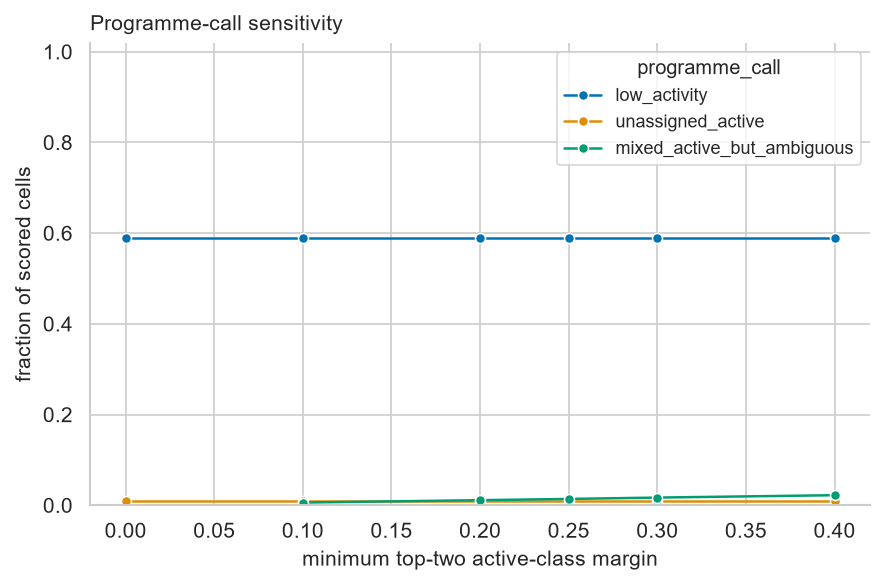

In [249]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.lineplot(
    data=uncertain,
    x="margin",
    y="fraction_cells",
    hue="programme_call",
    marker="o",
    ax=ax,
)
ax.set_xlabel("minimum top-two active-class margin")
ax.set_ylabel("fraction of scored cells")
ax.set_ylim(0, 1.02)
ax.set_title("Programme-call sensitivity", loc="left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_figure(fig, fig_dir / "meta_programme_threshold_sensitivity", close=False, overwrite=False)
plt.show()


## Donor-centred cluster enrichment

These summaries show which programme score is relatively elevated in each
Leiden cluster after subtracting each donor-condition unit's overall mean.
They do not define cell identities or programme prevalence.

In [250]:
cluster_frame = class_scores.join(
    scored_obs[[cluster_key, "analysis_unit", condition_key]]
)


In [251]:
unit_means = cluster_frame.groupby("analysis_unit", observed=True)[
    candidate_hallmarks
].mean()


In [252]:
cluster_unit_means = cluster_frame.groupby(
    [cluster_key, "analysis_unit"], observed=True
)[candidate_hallmarks].mean()


In [253]:
cluster_unit_deviation = cluster_unit_means.copy()


In [254]:
for cluster, unit in cluster_unit_deviation.index:
    cluster_unit_deviation.loc[cluster, unit] -= unit_means.loc[unit]


In [255]:
cluster_deviation = cluster_unit_deviation.groupby(level=0, observed=True).agg(
    ["mean", "median", "count"]
)


In [256]:
cluster_rows = []


In [257]:
for cluster, values in cluster_unit_deviation.groupby(level=0, observed=True):
    values = values.droplevel(0)
    mean_deviation = values.mean(axis=0)
    supported = len(values) >= min_units_per_cluster
    top_class = mean_deviation.idxmax() if supported else "insufficient_support"
    loo_top = []
    if supported:
        for unit in values.index:
            loo_top.append(values.drop(index=unit).mean(axis=0).idxmax())
    cluster_rows.append(
        {
            cluster_key: cluster,
            "n_analysis_units": len(values),
            "leading_relative_enrichment": top_class,
            "leading_mean_deviation": (
                float(mean_deviation.loc[top_class]) if supported else np.nan
            ),
            "loo_leading_class_agreement": (
                float(np.mean(np.asarray(loo_top) == top_class)) if loo_top else np.nan
            ),
        }
    )


In [258]:
cluster_stability = pd.DataFrame(cluster_rows)


In [259]:
cluster_stability.to_csv(
    df_dir / "meta_programme_cluster_donor_stability.csv", index=False
)


In [260]:
display(cluster_stability)


,epi_leiden,n_analysis_units,leading_relative_enrichment,leading_mean_deviation,loo_leading_class_agreement
0,0,28,Neural Lineage,0.073381,1.0000
1,1,28,Respiration,0.121508,1.0000
2,2,27,Haematological Lineage,0.260014,1.0000
3,3,1,insufficient_support,NaN,NaN
4,4,28,Stress or Hypoxia,0.863937,1.0000
5,5,2,insufficient_support,NaN,NaN
6,6,28,Cell Cycle,3.366822,1.0000
7,7,24,Interferon and MHC II,0.967805,1.0000
8,8,16,Mesenchymal,1.170866,0.9375
9,9,23,Senescence,0.926791,1.0000


In [261]:
cluster_heatmap = cluster_unit_deviation.groupby(level=0, observed=True).mean().T


In [262]:
cluster_heatmap = cluster_heatmap.reindex(candidate_hallmarks)


In [263]:
supported_clusters = cluster_stability.loc[
    cluster_stability["n_analysis_units"].ge(min_units_per_cluster), cluster_key
]


In [264]:
cluster_heatmap = cluster_heatmap.loc[:, supported_clusters]


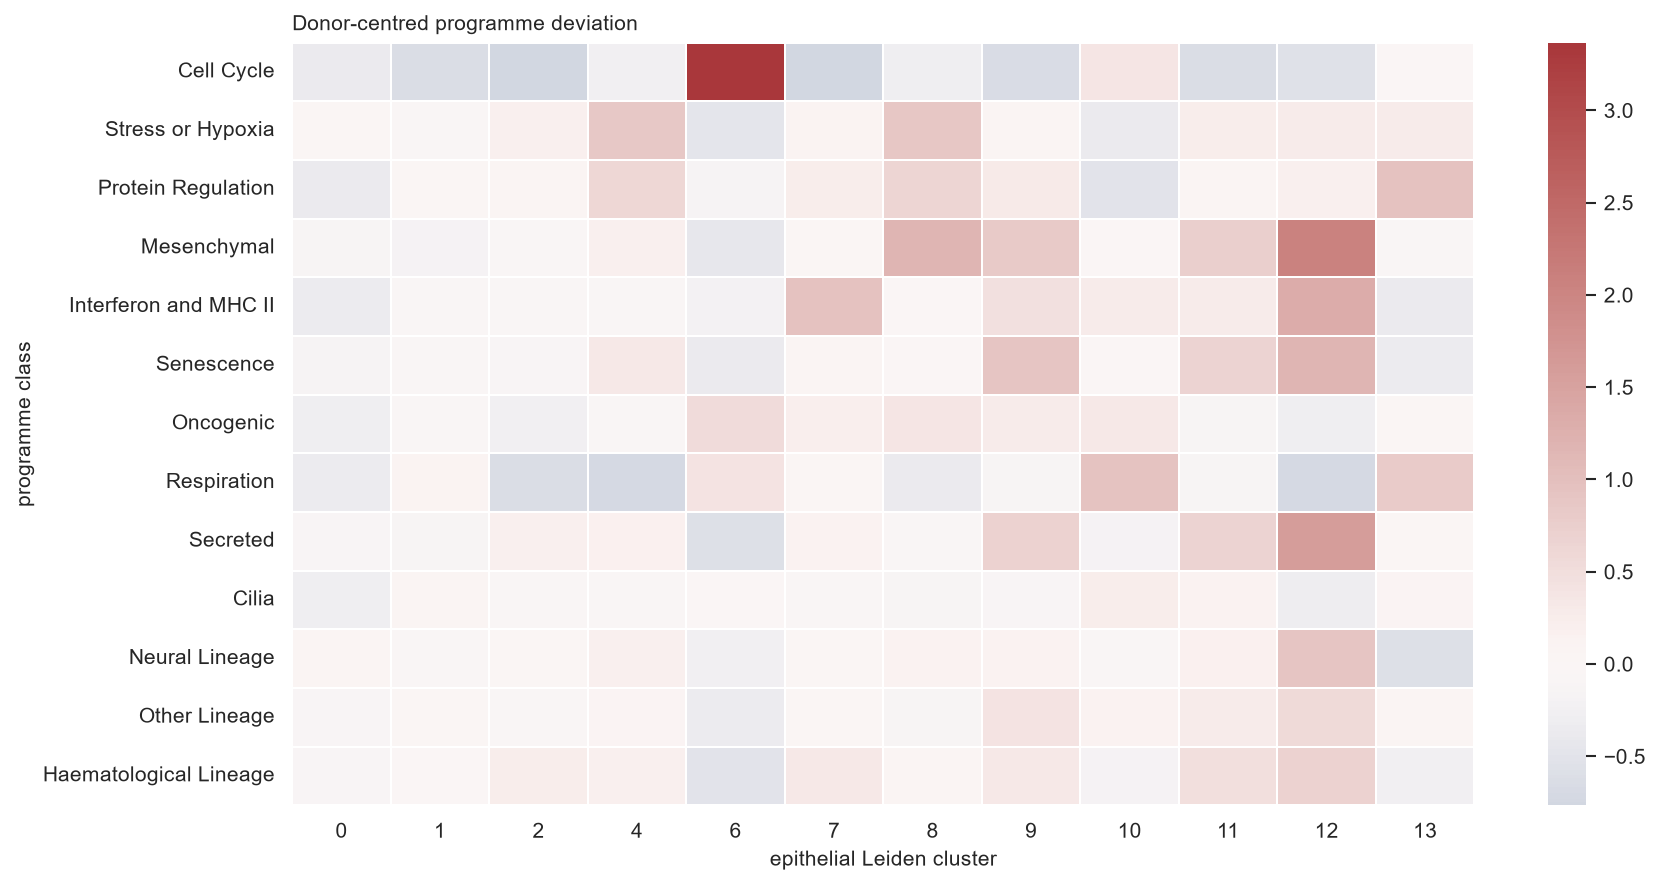

In [265]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(
    cluster_heatmap, cmap="vlag", center=0, linewidths=0.2, linecolor="white", ax=ax
)
ax.set_xlabel("epithelial Leiden cluster")
ax.set_ylabel("programme class")
ax.set_title("Donor-centred programme deviation", loc="left")
fig.tight_layout()
save_figure(fig, fig_dir / "meta_programme_cluster_donor_deviation", close=False, overwrite=False)
plt.show()


## Donor-level programme calls

Fractions use formal matched-null calls. Low-activity and ambiguous cells stay
in the denominator. Technical libraries are averaged within donor by
condition before condition summaries and permutation tests.

In [266]:
assignment = scored_obs[
    [
        sample_key,
        "analysis_unit",
        condition_key,
        "n_genes_by_counts",
        "tumour_derived_cnv_high",
        "g1_cell",
        "phase",
    ]
].copy()


In [267]:
assignment[condition_key] = assignment[condition_key].astype(str)


In [268]:
assignment["programme_call"] = cell_summary["programme_call"].astype(str)


In [269]:
composition_categories = candidate_hallmarks + [
    "low_activity",
    "mixed_active_but_ambiguous",
    "unassigned_active",
]


In [270]:
def composition_by_unit(frame):
    sample_profiles = pd.crosstab(
        [frame[sample_key], frame["analysis_unit"], frame[condition_key]],
        frame["programme_call"],
        normalize="index",
    ).reset_index()
    for category in composition_categories:
        if category not in sample_profiles:
            sample_profiles[category] = 0.0
    unit_profiles = (
        sample_profiles.groupby(["analysis_unit", condition_key], observed=True)[
            composition_categories
        ]
        .mean()
        .reset_index()
    )
    unit_profiles[condition_key] = unit_profiles[condition_key].astype(str)
    assert np.allclose(unit_profiles[composition_categories].sum(axis=1), 1.0)
    return (sample_profiles, unit_profiles)


In [271]:
sample_composition, unit_composition = composition_by_unit(assignment)


In [272]:
min_gene_assignment = assignment[assignment["n_genes_by_counts"] >= 500].copy()


In [273]:
sample_composition_min_genes, unit_composition_min_genes = composition_by_unit(
    min_gene_assignment
)


In [274]:
cnv_high_assignment = assignment[assignment["tumour_derived_cnv_high"]].copy()


In [275]:
cnv_high_sample_sizes = cnv_high_assignment.groupby(sample_key, observed=True).size()


In [276]:
cnv_high_eligible_samples = cnv_high_sample_sizes[
    cnv_high_sample_sizes >= min_cells_per_sample
].index


In [277]:
cnv_high_assignment = cnv_high_assignment[
    cnv_high_assignment[sample_key].isin(cnv_high_eligible_samples)
]


In [278]:
sample_composition_cnv_high, unit_composition_cnv_high = composition_by_unit(
    cnv_high_assignment
)


In [279]:
cnv_high_g1_assignment = assignment[
    assignment["tumour_derived_cnv_high"] & assignment["g1_cell"]
].copy()


In [280]:
cnv_high_g1_sample_sizes = cnv_high_g1_assignment.groupby(
    sample_key, observed=True
).size()


In [281]:
cnv_high_g1_eligible_samples = cnv_high_g1_sample_sizes[
    cnv_high_g1_sample_sizes >= min_cells_per_sample
].index


In [282]:
cnv_high_g1_assignment = cnv_high_g1_assignment[
    cnv_high_g1_assignment[sample_key].isin(cnv_high_g1_eligible_samples)
]


In [283]:
sample_composition_cnv_high_g1, unit_composition_cnv_high_g1 = composition_by_unit(
    cnv_high_g1_assignment
)


In [284]:
complexity_sensitivity = (
    assignment.assign(low_complexity=assignment["n_genes_by_counts"] < 500)
    .groupby(condition_key, observed=True)
    .agg(
        n_tumour_derived_cells=("low_complexity", "size"),
        n_below_500_genes=("low_complexity", "sum"),
    )
    .reset_index()
)


In [285]:
cnv_high_eligibility = (
    assignment.groupby([sample_key, "analysis_unit", condition_key], observed=True)
    .agg(
        n_tumour_derived_cells=("tumour_derived_cnv_high", "size"),
        n_cnv_high=("tumour_derived_cnv_high", "sum"),
        n_cnv_high_g1=(
            "g1_cell",
            lambda x: int(
                (x & assignment.loc[x.index, "tumour_derived_cnv_high"]).sum()
            ),
        ),
    )
    .reset_index()
)


In [286]:
cnv_high_eligibility["included"] = (
    cnv_high_eligibility["n_cnv_high"] >= min_cells_per_sample
)


In [287]:
unit_composition.to_csv(df_dir / "meta_programme_donor_profiles.csv", index=False)


In [288]:
unit_composition_min_genes.to_csv(
    df_dir / "meta_programme_donor_profiles_min_500_genes.csv", index=False
)


In [289]:
unit_composition_cnv_high.to_csv(
    df_dir / "meta_programme_donor_profiles_cnv_high.csv", index=False
)


In [290]:
complexity_sensitivity.to_csv(
    df_dir / "meta_programme_min_genes_sensitivity.csv", index=False
)


In [291]:
cnv_high_eligibility.to_csv(
    df_dir / "meta_programme_cnv_high_eligibility.csv", index=False
)


In [292]:
display(complexity_sensitivity.round(4))


,condition,n_tumour_derived_cells,n_below_500_genes
0,ER+,54256,8829
1,HER2+,16515,1496
2,TN,26194,1180


In [293]:
display(cnv_high_eligibility)


,sample,analysis_unit,condition,n_tumour_derived_cells,n_cnv_high,n_cnv_high_g1,included
0,GSM4909281_TN-MH0126,MH0126__TN,TN,1078,892,308,True
1,GSM4909282_TN-MH0135,MH0135__TN,TN,12113,5921,1485,True
2,GSM4909285_TN-B1-MH4031,MH4031__TN,TN,4706,1243,593,True
3,GSM4909286_TN-B1-MH0131,MH0131__TN,TN,4846,490,299,True
4,GSM4909287_TN-B1-Tum0554,Tum0554__TN,TN,2626,1182,352,True
5,GSM4909288_TN-B1-MH0177,MH0177__TN,TN,825,260,117,True
6,GSM4909289_HER2-AH0308,AH0308__HER2+,HER2+,3013,513,305,True
7,GSM4909290_HER2-PM0337,PM0337__HER2+,HER2+,2981,587,222,True
8,GSM4909291_HER2-MH0031,MH0031__HER2+,HER2+,1450,1260,810,True
9,GSM4909292_HER2-MH0069,MH0069__HER2+,HER2+,239,169,99,True


In [294]:
unit_composition_cnv_high_g1.to_csv(
    df_dir / "meta_programme_donor_profiles_cnv_high_g1.csv", index=False
)


In [295]:
condition_order = ["TN", "HER2+", "ER+"]


In [296]:
condition_palette = {"TN": "#976391", "HER2+": "#2CA02C", "ER+": "#F46036"}


In [297]:
long_composition = unit_composition.melt(
    id_vars=["analysis_unit", condition_key],
    value_vars=candidate_hallmarks,
    var_name="programme",
    value_name="fraction",
)


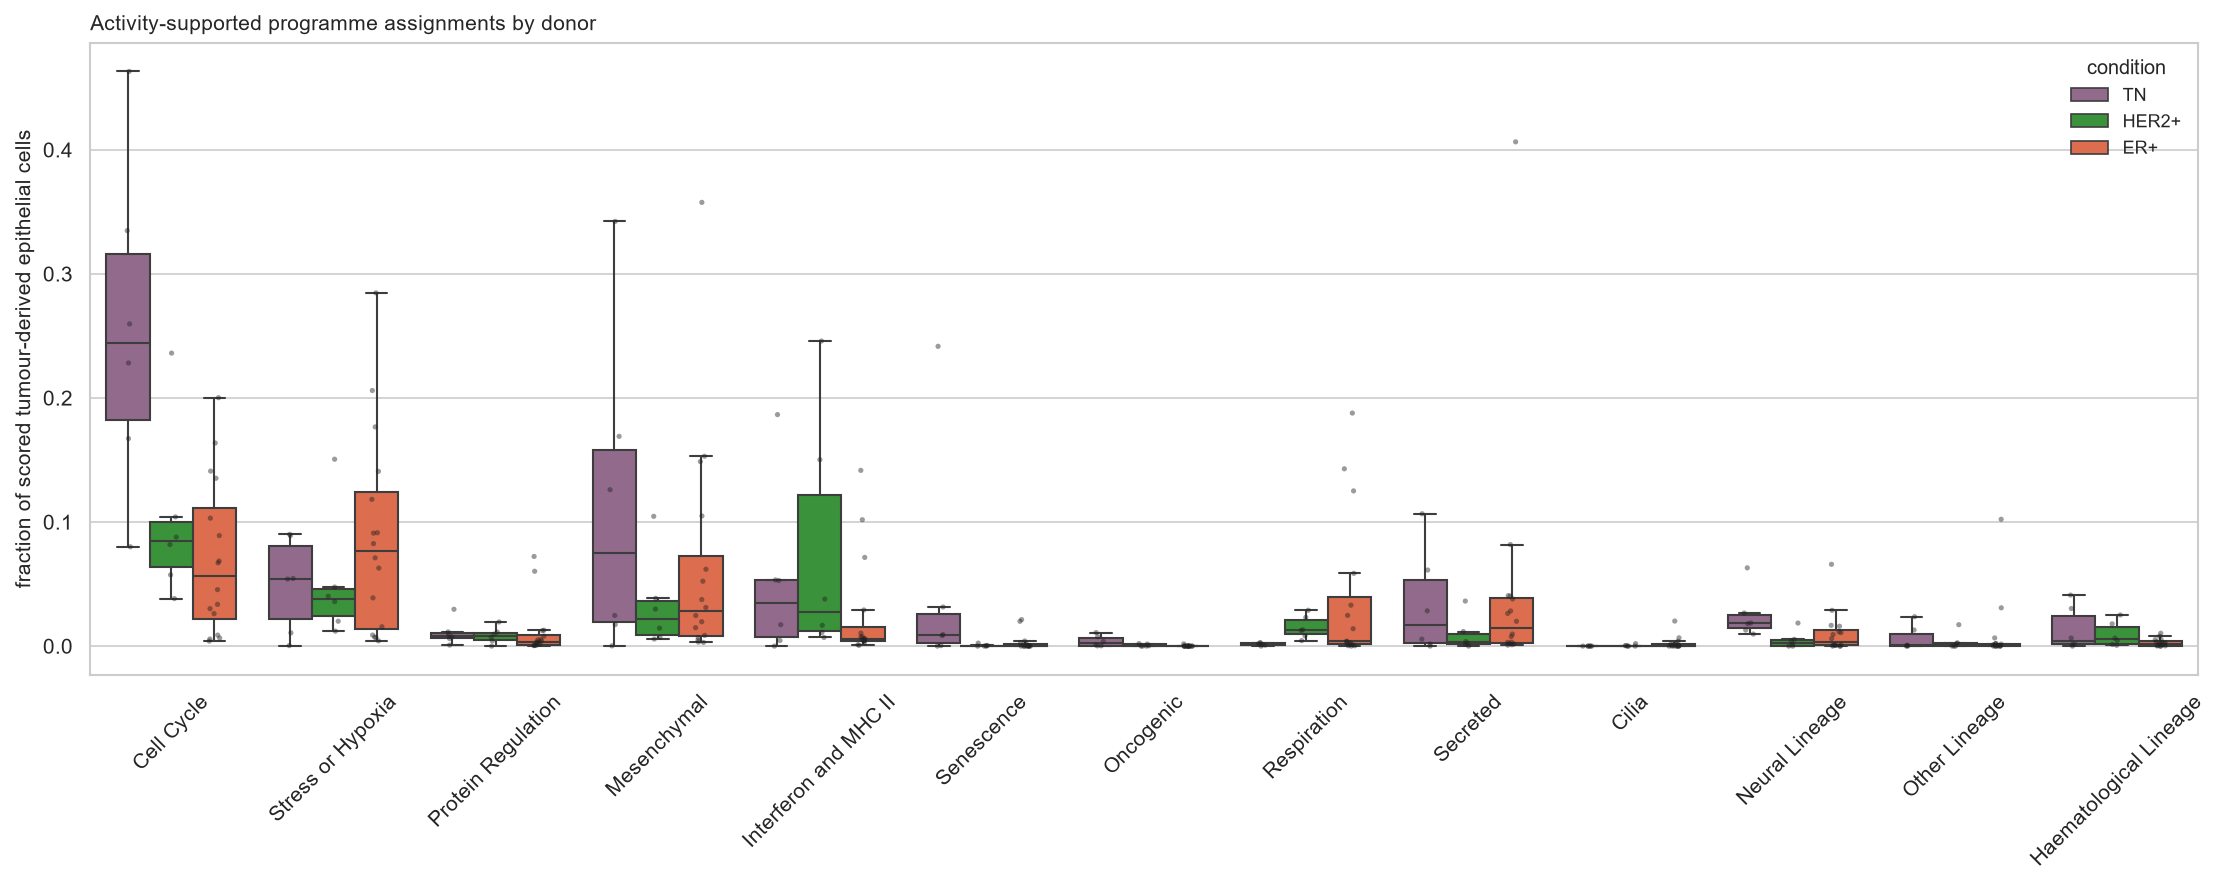

In [298]:
fig, ax = plt.subplots(figsize=(15, 6))
sns.boxplot(
    data=long_composition,
    x="programme",
    y="fraction",
    hue=condition_key,
    order=candidate_hallmarks,
    hue_order=condition_order,
    palette=condition_palette,
    showfliers=False,
    ax=ax,
)
sns.stripplot(
    data=long_composition,
    x="programme",
    y="fraction",
    hue=condition_key,
    order=candidate_hallmarks,
    hue_order=condition_order,
    dodge=True,
    palette={condition: "#222222" for condition in condition_order},
    alpha=0.45,
    size=2.5,
    legend=False,
    ax=ax,
)
ax.set_xlabel("")
ax.set_ylabel("fraction of scored tumour-derived epithelial cells")
ax.set_title("Activity-supported programme assignments by donor", loc="left")
ax.tick_params(axis="x", rotation=45)
ax.legend(frameon=False, title="condition")
fig.tight_layout()
save_figure(fig, fig_dir / "meta_programme_programme_donor_composition", close=False, overwrite=False)
plt.show()


## Condition-level programme overview

Each donor-condition unit contributes once. The stacked bars include
low-activity and ambiguous cells, so every bar sums to one. This is an overview;
the donor-level box-and-point plot above retains the biological variability.

In [299]:
overview_order = candidate_hallmarks + [
    "low_activity",
    "mixed_active_but_ambiguous",
    "unassigned_active",
]


In [300]:
overview_palette = {**programme_palette, **uncertainty_palette}


In [301]:
condition_composition = (
    unit_composition.groupby(condition_key, observed=True)[overview_order]
    .mean()
    .reindex(condition_order)
)


In [302]:
n_units = unit_composition.groupby(condition_key, observed=True)[
    "analysis_unit"
].nunique()


In [303]:
n_cells = scored_obs.groupby(condition_key, observed=True).size()


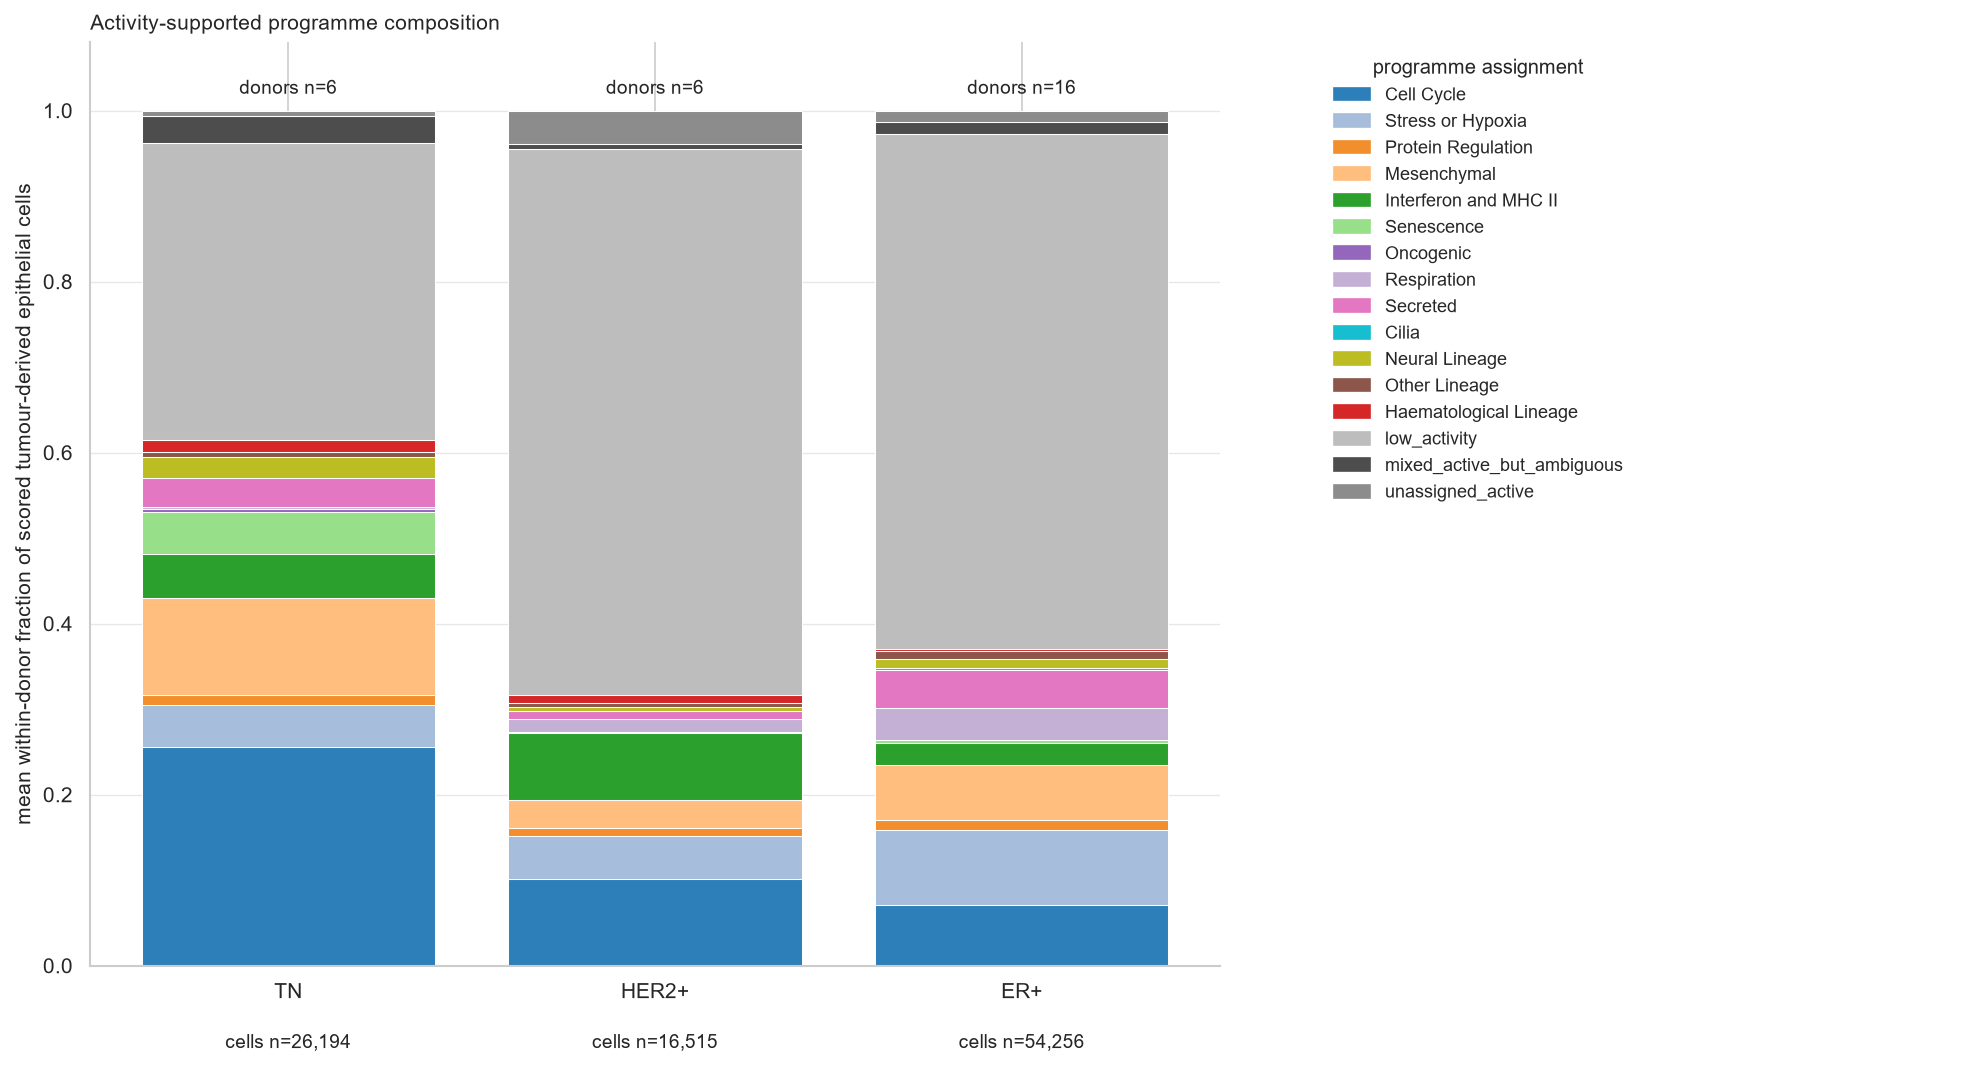

In [304]:
fig, (ax, legend_ax) = plt.subplots(
    1,
    2,
    figsize=(13, 7),
    gridspec_kw={"width_ratios": [3.2, 1.8], "wspace": 0.1},
    layout="constrained",
)
positions = np.arange(len(condition_order))
bottom = np.zeros(len(condition_order))
for programme in overview_order:
    values = condition_composition[programme].to_numpy()
    ax.bar(
        positions,
        values,
        bottom=bottom,
        color=overview_palette[programme],
        edgecolor="white",
        linewidth=0.5,
        label=programme,
    )
    bottom += values
for position, condition in enumerate(condition_order):
    ax.text(
        position,
        1.015,
        f"donors n={int(n_units.get(condition, 0))}",
        ha="center",
        va="bottom",
        fontsize=9,
    )
    ax.text(
        position,
        -0.08,
        f"cells n={int(n_cells.get(condition, 0)):,}",
        ha="center",
        va="top",
        fontsize=9,
    )
ax.set_xticks(positions, condition_order)
ax.set_ylim(0, 1.08)
ax.set_ylabel("mean within-donor fraction of scored tumour-derived epithelial cells")
ax.set_xlabel("")
ax.set_title("Activity-supported programme composition", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E5E7EB", linewidth=0.6)
ax.set_axisbelow(True)
legend_ax.axis("off")
legend_ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=overview_palette[x], label=x)
        for x in overview_order
    ],
    title="programme assignment",
    loc="upper left",
    frameon=False,
)
save_figure(fig, fig_dir / "meta_programme_programme_composition_by_condition", close=False, overwrite=False)
plt.show()


In [305]:
condition_composition.to_csv(
    df_dir / "meta_programme_programme_composition_by_condition.csv"
)


## Cluster-enrichment decomposition

This panel shows all 41 individual meta-programmes, grouped by their parent
class, across the cluster groups defined above. Dot colour is the mean
donor-centred deviation and dot size is the fraction of donor-condition units
with a positive deviation. Because the same MP scores define the cluster groups,
this is a descriptive quality-control figure rather than independent validation.
Row labels identify the largest relative deviation only; they do not establish
selective or statistically significant programme activity.

A dot is omitted when no donor-condition unit has a positive deviation.
A blank does not establish programme absence; the full signed deviations remain
in the exported source-data table.

In [306]:
cluster_display = cluster_stability.copy()


In [307]:
cluster_display["display_group"] = cluster_display[
    "leading_relative_enrichment"
].astype(str)


In [308]:
stable = cluster_display["n_analysis_units"].ge(
    min_units_per_cluster
) & cluster_display["loo_leading_class_agreement"].ge(0.8)


In [309]:
cluster_display.loc[~stable, "display_group"] = "Unresolved"


In [310]:
cluster_group_map = cluster_display.set_index(cluster_key)["display_group"]


In [311]:
cluster_group_map.index = cluster_group_map.index.astype(str)


In [312]:
group_meta = scored_obs[[cluster_key, "analysis_unit"]].copy()


In [313]:
group_meta["cluster_string"] = group_meta[cluster_key].astype(str)


In [314]:
group_meta["display_group"] = group_meta["cluster_string"].map(cluster_group_map)


In [315]:
assert group_meta["display_group"].notna().all()


In [316]:
unit_overall_mp = (
    mp_global_z.join(group_meta[["analysis_unit"]])
    .groupby("analysis_unit", observed=True)
    .mean()
)


In [317]:
unit_group_mp = (
    mp_global_z.join(group_meta[["analysis_unit", "display_group"]])
    .groupby(["analysis_unit", "display_group"], observed=True)
    .mean()
)


In [318]:
unit_group_deviation = unit_group_mp.copy()


In [319]:
for unit, group in unit_group_deviation.index:
    unit_group_deviation.loc[unit, group] -= unit_overall_mp.loc[unit]


In [320]:
group_mp_long = unit_group_deviation.reset_index().melt(
    id_vars=["analysis_unit", "display_group"],
    value_vars=list(mp_global_z.columns),
    var_name="mp_name",
    value_name="unit_centred_mp_deviation",
)


In [321]:
group_mp_summary = group_mp_long.groupby(
    ["display_group", "mp_name"], observed=True, as_index=False
).agg(
    mean_unit_centred_deviation=("unit_centred_mp_deviation", "mean"),
    fraction_units_positive=("unit_centred_mp_deviation", lambda x: (x > 0).mean()),
    n_units=("unit_centred_mp_deviation", "size"),
)


In [322]:
group_order = [
    group
    for group in candidate_hallmarks
    if group in set(group_mp_summary["display_group"])
]


In [323]:
if "Unresolved" in set(group_mp_summary["display_group"]):
    group_order.append("Unresolved")


In [324]:
mp_order = [
    mp
    for parent_class, members in meta_programme_hallmarks.items()
    for mp in members
    if mp in mp_global_z.columns
]


In [325]:
mp_axis_labels = {}


In [326]:
for mp in mp_order:
    corrected = mp.replace("Cell Cylce", "Cell Cycle")
    mp_id, description = corrected.split(" ", 1)
    mp_axis_labels[mp] = f"{mp_id}  {description}"


In [327]:
mp_x = {}


In [328]:
parent_spans = []


In [329]:
x_cursor = 0.0


In [330]:
for parent_class, members in meta_programme_hallmarks.items():
    present = [mp for mp in members if mp in mp_order]
    if not present:
        continue
    start = x_cursor
    for mp in present:
        mp_x[mp] = x_cursor
        x_cursor += 1.0
    end = x_cursor - 1.0
    parent_spans.append((parent_class, start, end))
    x_cursor += 0.45


In [331]:
plot_summary = group_mp_summary.copy()


In [332]:
plot_summary["x"] = plot_summary["mp_name"].map(mp_x)


In [333]:
plot_summary["y"] = plot_summary["display_group"].map(
    {group: i for i, group in enumerate(group_order)}
)


In [334]:
plot_summary = plot_summary.dropna(subset=["x", "y"])


In [335]:
limit = float(np.quantile(np.abs(plot_summary["mean_unit_centred_deviation"]), 0.98))


In [336]:
limit = max(limit, 0.1)


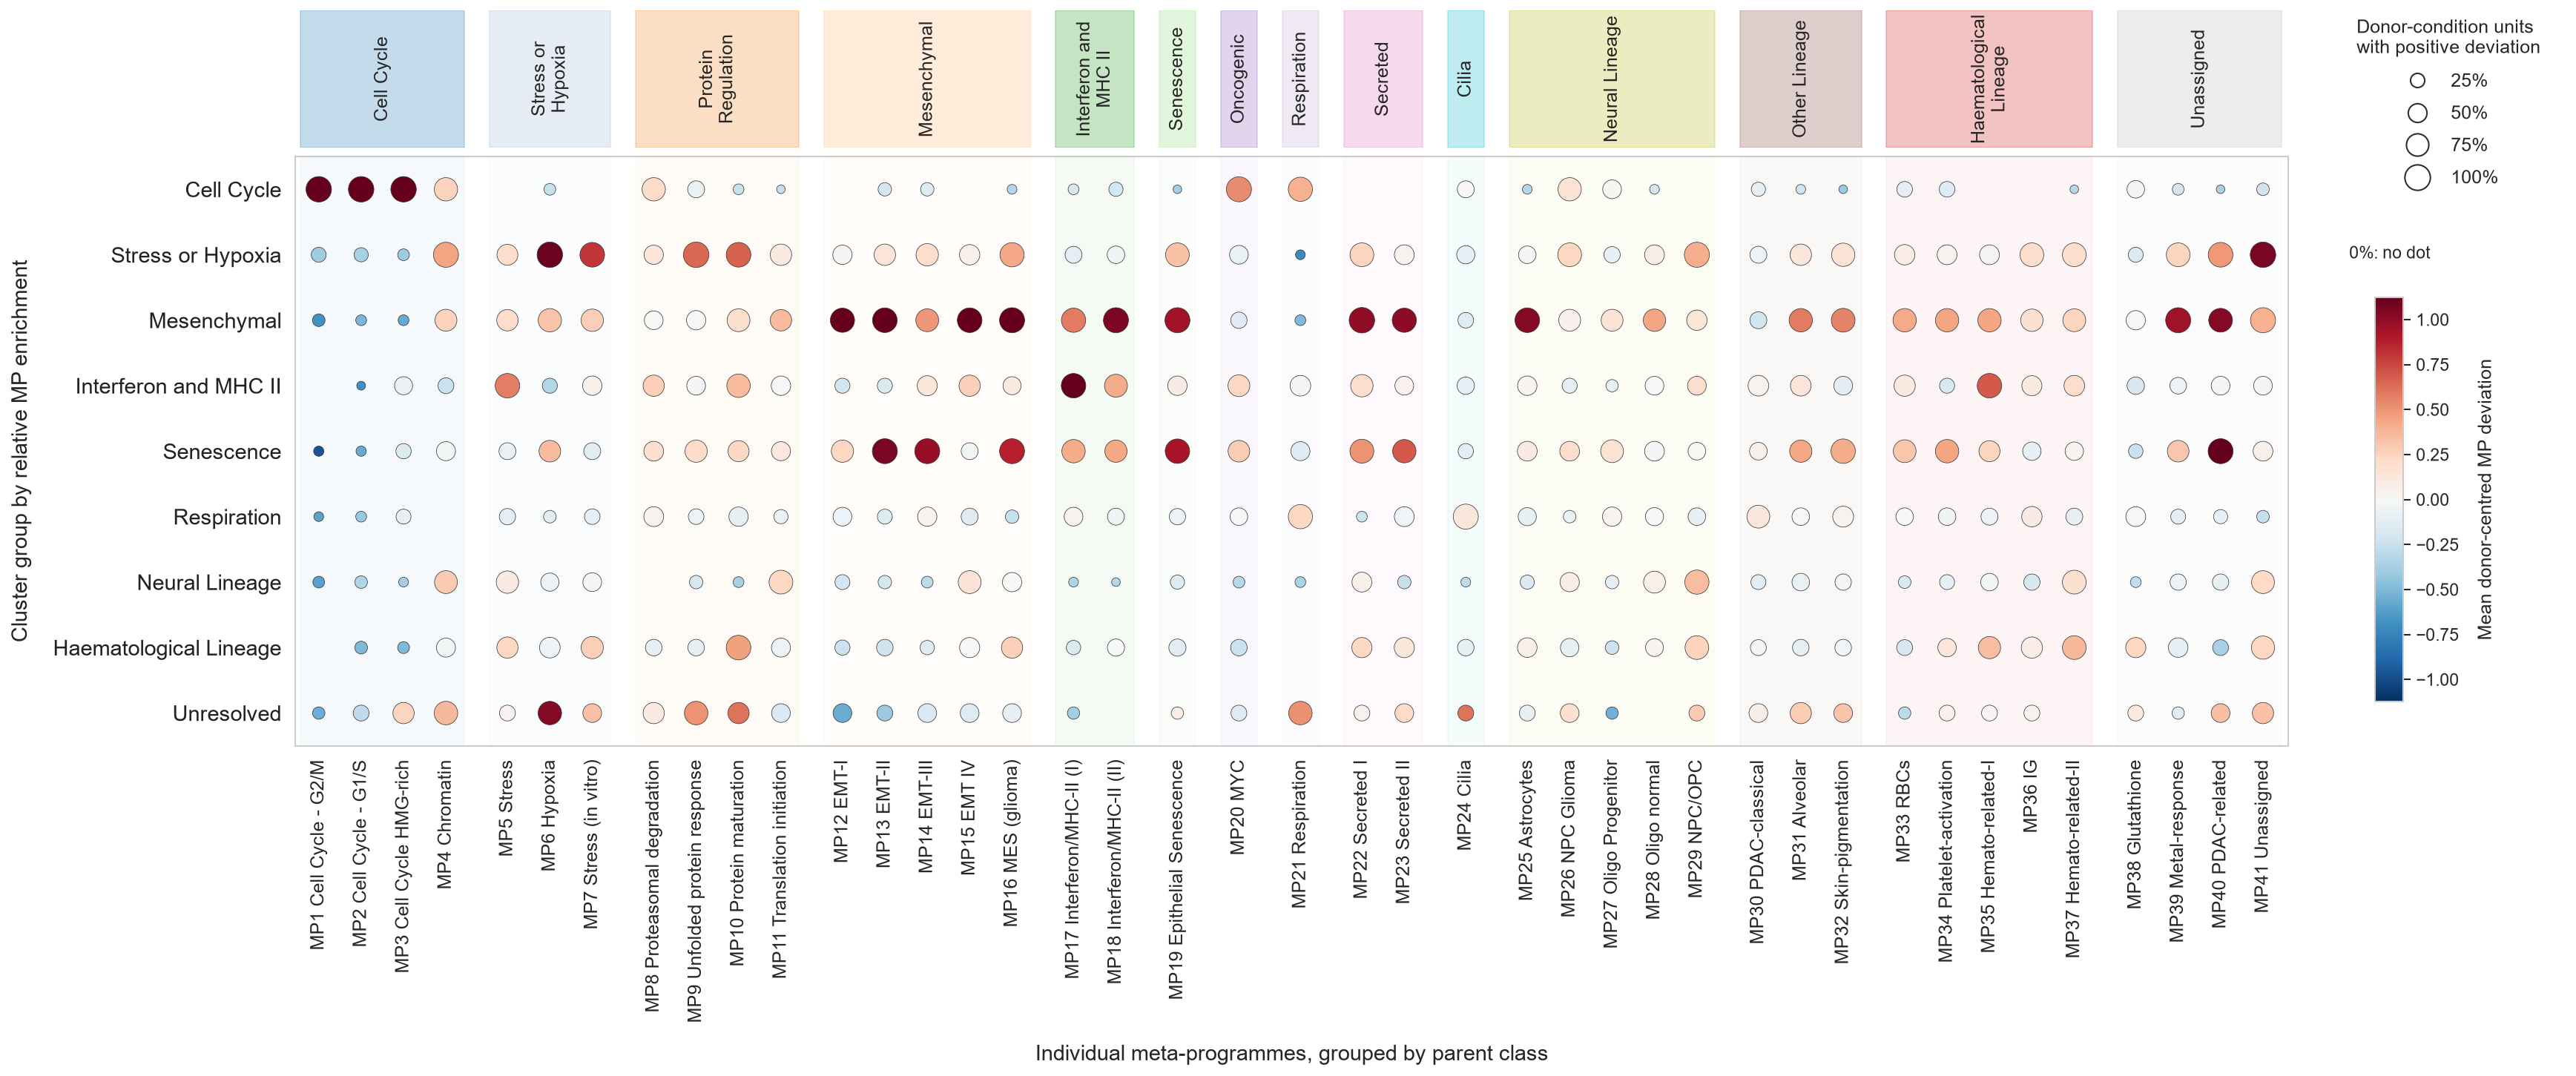

In [337]:
fig = plt.figure(figsize=(24, max(9.5, 0.58 * len(group_order) + 4.5)))
grid = fig.add_gridspec(
    2,
    2,
    height_ratios=[1.15, max(4.2, 0.55 * len(group_order))],
    width_ratios=[12, 1.3],
    hspace=0.025,
    wspace=0.055,
)
band_ax = fig.add_subplot(grid[0, 0])
ax = fig.add_subplot(grid[1, 0], sharex=band_ax)
legend_ax = fig.add_subplot(grid[:, 1])
legend_ax.axis("off")
colourbar_ax = legend_ax.inset_axes([0.12, 0.06, 0.13, 0.55])
visible_points = plot_summary.loc[plot_summary["fraction_units_positive"].gt(0)].copy()
points = ax.scatter(
    visible_points["x"],
    visible_points["y"],
    s=22 + 250 * visible_points["fraction_units_positive"],
    c=visible_points["mean_unit_centred_deviation"],
    cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit),
    edgecolor="#303030",
    linewidth=0.35,
    zorder=3,
)
parent_palette = {**programme_palette, "Unassigned": "#BDBDBD"}
parent_labels = {
    "Stress or Hypoxia": "Stress or\nHypoxia",
    "Protein Regulation": "Protein\nRegulation",
    "Interferon and MHC II": "Interferon and\nMHC II",
    "Haematological Lineage": "Haematological\nLineage",
}
for parent_class, start, end in parent_spans:
    colour = parent_palette.get(parent_class, "#BDBDBD")
    band_ax.axvspan(start - 0.43, end + 0.43, color=colour, alpha=0.28)
    band_ax.text(
        (start + end) / 2,
        0.5,
        parent_labels.get(parent_class, parent_class),
        rotation=90,
        ha="center",
        va="center",
        fontsize=12,
    )
    ax.axvspan(start - 0.43, end + 0.43, color=colour, alpha=0.045, zorder=0)
band_ax.set_ylim(0, 1)
band_ax.axis("off")
readable_mp_labels = [" ".join(mp_axis_labels[mp].split()) for mp in mp_order]
ax.set_xticks(
    [mp_x[mp] for mp in mp_order],
    readable_mp_labels,
    rotation=90,
    fontsize=12,
    ha="center",
    va="top",
)
ax.set_yticks(range(len(group_order)), group_order, fontsize=14)
ax.tick_params(axis="both", length=0, pad=9)
ax.set_xlim(-0.55, x_cursor - 0.85)
ax.set_ylim(len(group_order) - 0.5, -0.5)
ax.set_xlabel(
    "Individual meta-programmes, grouped by parent class", fontsize=14, labelpad=14
)
ax.set_ylabel("Cluster group by relative MP enrichment", fontsize=14, labelpad=14)
ax.grid(False, which="both", axis="both")
for tick in ax.get_yticklabels():
    tick.set_color("#222222")
colourbar = fig.colorbar(points, cax=colourbar_ax)
colourbar.set_label("Mean donor-centred MP deviation", fontsize=12, labelpad=12)
colourbar.ax.tick_params(labelsize=11)
if colourbar.solids is not None:
    colourbar.solids.set_rasterized(False)
legend_ax.legend(
    handles=[
        Line2D(
            [],
            [],
            linestyle="none",
            marker="o",
            markersize=np.sqrt(22 + 250 * fraction),
            markerfacecolor="white",
            markeredgecolor="#303030",
            label=f"{fraction:.0%}",
        )
        for fraction in [0.25, 0.5, 0.75, 1.0]
    ],
    title="Donor-condition units\nwith positive deviation",
    loc="upper left",
    bbox_to_anchor=(0, 1),
    frameon=False,
    fontsize=12,
    title_fontsize=12,
    labelspacing=0.8,
    borderaxespad=0,
)
legend_ax.text(
    0,
    0.68,
    "0%: no dot",
    transform=legend_ax.transAxes,
    fontsize=11,
    ha="left",
    va="top",
)
fig.subplots_adjust(left=0.135, right=0.985, bottom=0.3, top=0.98)
save_figure(fig, fig_dir / "meta_programme_cluster_enrichment_bubble", close=False, overwrite=False)
plt.show()


In [338]:
group_mp_summary.to_csv(
    df_dir / "meta_programme_cluster_enrichment_bubble.csv", index=False
)


In [339]:
plot_summary.to_csv(
    df_dir / "meta_programme_cluster_enrichment_bubble_plotted.csv", index=False
)


In [340]:
group_mp_long.to_csv(
    df_dir / "meta_programme_cluster_enrichment_by_unit.csv", index=False
)


## Programme-wise condition tests

Each programme is tested across conditions with a donor-level Kruskal statistic
and 9,999 label permutations. Holm correction controls multiplicity across the
13 parent classes. The asymptotic p-value is retained only as a diagnostic.

In [341]:
def kruskal_permutation_test(values, labels, levels, permutations, seed):
    values = np.asarray(values, dtype=float)
    labels = np.asarray(labels, dtype=str)
    if np.allclose(values, values[0]):
        return (0.0, 1.0, 1.0)
    groups = [values[labels == level] for level in levels]
    observed, asymptotic_p = kruskal(*groups)
    ranks = rankdata(values)
    _, tie_counts = np.unique(values, return_counts=True)
    n = len(values)
    tie_correction = 1 - np.sum(tie_counts**3 - tie_counts) / (n**3 - n)
    group_sizes = {level: np.sum(labels == level) for level in levels}
    rng = np.random.default_rng(seed)
    extreme = 0
    for _ in range(permutations):
        shuffled = rng.permutation(labels)
        rank_term = sum(
            (
                ranks[shuffled == level].sum() ** 2 / group_sizes[level]
                for level in levels
            )
        )
        permuted = 12 * rank_term / (n * (n + 1)) - 3 * (n + 1)
        permuted /= tie_correction
        extreme += permuted >= observed - 1e-12
    permutation_p = (extreme + 1) / (permutations + 1)
    return (float(observed), float(asymptotic_p), float(permutation_p))


In [342]:
def programme_condition_tests(composition, label):
    rows = []
    labels = composition[condition_key].astype(str).to_numpy()
    for programme in candidate_hallmarks:
        statistic, asymptotic_p, permutation_p = kruskal_permutation_test(
            composition[programme],
            labels,
            condition_order,
            n_permutations,
            stable_seed(f"kruskal::{label}::{programme}"),
        )
        rows.append(
            {
                "programme": programme,
                "kruskal_h": statistic,
                "p_asymptotic": asymptotic_p,
                "p_permutation": permutation_p,
            }
        )
    result = pd.DataFrame(rows)
    result["p_holm"] = multipletests(result["p_permutation"], method="holm")[1]
    return result


In [343]:
programme_tests = programme_condition_tests(unit_composition, "primary")


In [344]:
programme_tests_min_genes = programme_condition_tests(
    unit_composition_min_genes, "min_500_genes"
)


In [345]:
programme_tests_cnv_high = programme_condition_tests(
    unit_composition_cnv_high, "cnv_high"
)


In [346]:
programme_tests.to_csv(df_dir / "meta_programme_condition_tests.csv", index=False)


In [347]:
programme_tests_cnv_high_g1 = programme_condition_tests(
    unit_composition_cnv_high_g1, "cnv_high_g1"
)


In [348]:
programme_tests_min_genes.to_csv(
    df_dir / "meta_programme_condition_tests_min_500_genes.csv", index=False
)


In [349]:
programme_tests_cnv_high.to_csv(
    df_dir / "meta_programme_condition_tests_cnv_high.csv", index=False
)


In [350]:
display(programme_tests.sort_values("p_permutation").round(4))


,programme,kruskal_h,p_asymptotic,p_permutation,p_holm
6,Oncogenic,15.9020,0.0004,0.0001,0.0013
0,Cell Cycle,9.8374,0.0073,0.0037,0.0444
10,Neural Lineage,6.9741,0.0306,0.0259,0.2849
7,Respiration,5.7844,0.0555,0.0509,0.5090
9,Cilia,5.2795,0.0714,0.0718,0.6462
5,Senescence,5.0772,0.0790,0.0729,0.6462
4,Interferon and MHC II,4.2743,0.1180,0.1171,0.8197
12,Haematological Lineage,2.4100,0.2997,0.3169,1.0000
8,Secreted,1.5888,0.4519,0.4651,1.0000
2,Protein Regulation,1.5800,0.4538,0.4660,1.0000


In [351]:
display(programme_tests_min_genes.sort_values("p_permutation").round(4))


,programme,kruskal_h,p_asymptotic,p_permutation,p_holm
6,Oncogenic,19.7041,0.0001,0.0001,0.0013
0,Cell Cycle,9.4763,0.0088,0.0055,0.0660
7,Respiration,7.1935,0.0274,0.0240,0.2640
10,Neural Lineage,6.7051,0.0350,0.0270,0.2700
9,Cilia,5.4346,0.0661,0.0545,0.4905
5,Senescence,5.5870,0.0612,0.0602,0.4905
4,Interferon and MHC II,4.4676,0.1071,0.1072,0.7504
12,Haematological Lineage,1.9637,0.3746,0.3874,1.0000
2,Protein Regulation,1.6823,0.4312,0.4483,1.0000
8,Secreted,1.6110,0.4469,0.4606,1.0000


In [352]:
display(programme_tests_cnv_high.sort_values("p_permutation").round(4))


,programme,kruskal_h,p_asymptotic,p_permutation,p_holm
6,Oncogenic,19.0618,0.0001,0.0001,0.0013
0,Cell Cycle,11.0529,0.0040,0.0014,0.0168
5,Senescence,9.1744,0.0102,0.0096,0.1056
10,Neural Lineage,7.1000,0.0287,0.0223,0.2230
9,Cilia,5.7778,0.0556,0.0441,0.3969
7,Respiration,4.6586,0.0974,0.0959,0.7672
4,Interferon and MHC II,3.7957,0.1499,0.1435,1.0000
2,Protein Regulation,2.8589,0.2394,0.2454,1.0000
12,Haematological Lineage,1.7759,0.4115,0.4226,1.0000
8,Secreted,1.0322,0.5969,0.6067,1.0000


In [353]:
programme_tests_cnv_high_g1.to_csv(
    df_dir / "meta_programme_condition_tests_cnv_high_g1.csv", index=False
)


In [354]:
display(programme_tests_cnv_high_g1.sort_values("p_permutation").round(4))


,programme,kruskal_h,p_asymptotic,p_permutation,p_holm
6,Oncogenic,15.5431,0.0004,0.0004,0.0052
10,Neural Lineage,8.2670,0.0160,0.0114,0.1368
0,Cell Cycle,7.0587,0.0293,0.0209,0.2299
9,Cilia,6.3371,0.0421,0.0345,0.3450
5,Senescence,4.0131,0.1345,0.0984,0.8856
4,Interferon and MHC II,3.5667,0.1681,0.1705,1.0000
7,Respiration,3.4170,0.1811,0.1892,1.0000
2,Protein Regulation,3.2905,0.1930,0.2020,1.0000
3,Mesenchymal,2.5886,0.2741,0.2803,1.0000
1,Stress or Hypoxia,1.1407,0.5653,0.5780,1.0000


## Complete programme profile

Condition differences are tested on Hellinger-transformed donor-level
composition profiles with a Euclidean pseudo-F statistic and 9,999 label
permutations. A centroid-distance permutation test checks whether a global
result could reflect unequal within-condition dispersion. Pairwise tests are
interpreted only when the global test is significant.

In [355]:
def multivariate_f(values, labels):
    values = np.asarray(values, float)
    labels = np.asarray(labels)
    groups = np.unique(labels)
    grand_mean = values.mean(axis=0)
    total = np.square(values - grand_mean).sum()
    between = sum(
        (
            (labels == group).sum()
            * np.square(values[labels == group].mean(axis=0) - grand_mean).sum()
            for group in groups
        )
    )
    within = total - between
    statistic = between / (len(groups) - 1) / (within / (len(values) - len(groups)))
    return (float(statistic), float(between / total))


In [356]:
def permutation_test(values, labels, permutations, seed):
    observed, r_squared = multivariate_f(values, labels)
    rng = np.random.default_rng(seed)
    null = np.empty(permutations)
    for index in range(permutations):
        null[index], _ = multivariate_f(values, rng.permutation(labels))
    p_value = (1 + np.count_nonzero(null >= observed)) / (permutations + 1)
    return (observed, r_squared, p_value)


In [357]:
profile_values = np.sqrt(unit_composition[composition_categories].to_numpy(float))


In [358]:
profile_conditions = unit_composition[condition_key].astype(str).to_numpy()


In [359]:
global_f, global_r2, global_p = permutation_test(
    profile_values, profile_conditions, permutations=n_permutations, seed=random_seed
)


In [360]:
global_test = pd.DataFrame(
    [
        {
            "n_analysis_units": len(unit_composition),
            "n_profile_categories": len(composition_categories),
            "pseudo_f": global_f,
            "r_squared": global_r2,
            "p_value": global_p,
            "n_permutations": n_permutations,
            "seed": random_seed,
        }
    ]
)


In [361]:
global_test.to_csv(
    df_dir / "meta_programme_programme_global_permanova.csv", index=False
)


In [362]:
display(global_test.round(4))


,n_analysis_units,n_profile_categories,pseudo_f,r_squared,p_value,n_permutations,seed
0,28,16,2.5951,0.1719,0.0112,9999,0


In [363]:
sensitivity_values = np.sqrt(
    unit_composition_min_genes[composition_categories].to_numpy(float)
)


In [364]:
sensitivity_conditions = (
    unit_composition_min_genes[condition_key].astype(str).to_numpy()
)


In [365]:
sensitivity_f, sensitivity_r2, sensitivity_p = permutation_test(
    sensitivity_values,
    sensitivity_conditions,
    permutations=n_permutations,
    seed=stable_seed("permanova::min_500_genes"),
)


In [366]:
global_test_min_genes = pd.DataFrame(
    [
        {
            "n_analysis_units": len(unit_composition_min_genes),
            "n_profile_categories": len(composition_categories),
            "pseudo_f": sensitivity_f,
            "r_squared": sensitivity_r2,
            "p_value": sensitivity_p,
            "n_permutations": n_permutations,
            "seed_label": "permanova::min_500_genes",
        }
    ]
)


In [367]:
global_test_min_genes.to_csv(
    df_dir / "meta_programme_global_permanova_min_500_genes.csv", index=False
)


In [368]:
display(global_test_min_genes.round(4))


,n_analysis_units,n_profile_categories,pseudo_f,r_squared,p_value,n_permutations,seed_label
0,28,16,2.7824,0.1821,0.01,9999,permanova::min_500_genes


In [369]:
cnv_high_values = np.sqrt(
    unit_composition_cnv_high[composition_categories].to_numpy(float)
)


In [370]:
cnv_high_conditions = unit_composition_cnv_high[condition_key].astype(str).to_numpy()


In [371]:
cnv_high_f, cnv_high_r2, cnv_high_p = permutation_test(
    cnv_high_values,
    cnv_high_conditions,
    permutations=n_permutations,
    seed=stable_seed("permanova::cnv_high"),
)


In [372]:
global_test_cnv_high = pd.DataFrame(
    [
        {
            "n_analysis_units": len(unit_composition_cnv_high),
            "n_profile_categories": len(composition_categories),
            "pseudo_f": cnv_high_f,
            "r_squared": cnv_high_r2,
            "p_value": cnv_high_p,
            "n_permutations": n_permutations,
            "seed_label": "permanova::cnv_high",
        }
    ]
)


In [373]:
global_test_cnv_high.to_csv(
    df_dir / "meta_programme_global_permanova_cnv_high.csv", index=False
)


In [374]:
display(global_test_cnv_high.round(4))


,n_analysis_units,n_profile_categories,pseudo_f,r_squared,p_value,n_permutations,seed_label
0,27,16,3.318,0.2166,0.0023,9999,permanova::cnv_high


### Leave-one-donor-out sensitivity

The global profile test is repeated after omitting each donor-condition unit. This checks whether its interpretation depends on one donor.

In [375]:
loo_rows = []


In [376]:
analysis_units = unit_composition["analysis_unit"].astype(str).to_numpy()


In [377]:
for omitted_unit in analysis_units:
    keep = analysis_units != omitted_unit
    statistic, r_squared, p_value = permutation_test(
        profile_values[keep],
        profile_conditions[keep],
        permutations=n_permutations,
        seed=stable_seed(f"permanova_loo::{omitted_unit}"),
    )
    loo_rows.append(
        {
            "omitted_analysis_unit": omitted_unit,
            "omitted_condition": profile_conditions[~keep][0],
            "n_analysis_units": int(keep.sum()),
            "pseudo_f": statistic,
            "r_squared": r_squared,
            "p_value": p_value,
            "n_permutations": n_permutations,
        }
    )


In [378]:
permanova_loo = pd.DataFrame(loo_rows).sort_values("p_value")


In [379]:
permanova_loo.to_csv(
    df_dir / "meta_programme_programme_global_permanova_leave_one_donor_out.csv",
    index=False,
)


In [380]:
display(permanova_loo.round(4))


,omitted_analysis_unit,omitted_condition,n_analysis_units,pseudo_f,r_squared,p_value,n_permutations
15,MH0131__TN,TN,27,3.7475,0.2380,0.0012,9999
1,AH0319__ER+,ER+,27,2.9138,0.1954,0.0049,9999
21,MH0173__ER+,ER+,27,2.9383,0.1967,0.0052,9999
12,MH0069__HER2+,HER2+,27,2.6524,0.1810,0.0100,9999
9,MH0043__ER+,ER+,27,2.7860,0.1884,0.0109,9999
7,MH0040__ER+,ER+,27,2.6530,0.1811,0.0119,9999
19,MH0163__ER+,ER+,27,2.5273,0.1740,0.0127,9999
10,MH0056__ER+,ER+,27,2.4591,0.1701,0.0128,9999
17,MH0151__ER+,ER+,27,2.5893,0.1775,0.0129,9999
26,PM0360__ER+,ER+,27,2.5229,0.1737,0.0133,9999


In [381]:
def dispersion_statistic(values, labels):
    values = np.asarray(values, float)
    labels = np.asarray(labels)
    groups = np.unique(labels)
    distances = np.empty(len(values))
    for group in groups:
        mask = labels == group
        centroid = values[mask].mean(axis=0)
        distances[mask] = np.linalg.norm(values[mask] - centroid, axis=1)
    grand_mean = distances.mean()
    between = sum(
        (
            (labels == group).sum()
            * (distances[labels == group].mean() - grand_mean) ** 2
            for group in groups
        )
    )
    within = sum(
        (
            np.square(
                distances[labels == group] - distances[labels == group].mean()
            ).sum()
            for group in groups
        )
    )
    return float(between / (len(groups) - 1) / (within / (len(values) - len(groups))))


In [382]:
observed_dispersion = dispersion_statistic(profile_values, profile_conditions)


In [383]:
rng = np.random.default_rng(random_seed)


In [384]:
null_dispersion = np.array(
    [
        dispersion_statistic(profile_values, rng.permutation(profile_conditions))
        for _ in range(n_permutations)
    ]
)


In [385]:
dispersion_p = (1 + np.count_nonzero(null_dispersion >= observed_dispersion)) / (
    n_permutations + 1
)


In [386]:
dispersion_test = pd.DataFrame(
    [
        {
            "f_statistic": observed_dispersion,
            "p_value": dispersion_p,
            "n_permutations": n_permutations,
            "seed": random_seed,
        }
    ]
)


In [387]:
dispersion_test.to_csv(df_dir / "meta_programme_programme_permdisp.csv", index=False)


In [388]:
display(dispersion_test.round(4))


,f_statistic,p_value,n_permutations,seed
0,2.5388,0.2393,9999,0


In [389]:
pair_rows = []


In [390]:
condition_pairs = [("TN", "HER2+"), ("TN", "ER+"), ("HER2+", "ER+")]


In [391]:
for pair_index, (left, right) in enumerate(condition_pairs, start=1):
    keep = np.isin(profile_conditions, [left, right])
    statistic, r_squared, p_value = permutation_test(
        profile_values[keep],
        profile_conditions[keep],
        permutations=n_permutations,
        seed=random_seed + pair_index,
    )
    pair_rows.append(
        {
            "condition_a": left,
            "condition_b": right,
            "n_analysis_units": int(keep.sum()),
            "pseudo_f": statistic,
            "r_squared": r_squared,
            "p_value": p_value,
            "n_permutations": n_permutations,
            "seed": random_seed + pair_index,
        }
    )


In [392]:
pairwise_tests = pd.DataFrame(pair_rows)


In [393]:
pairwise_tests["p_holm"] = multipletests(pairwise_tests["p_value"], method="holm")[1]


In [394]:
pairwise_tests["interpret_only_if_global_significant"] = True


In [395]:
pairwise_tests.to_csv(
    df_dir / "meta_programme_programme_pairwise_permanova.csv", index=False
)


In [396]:
display(pairwise_tests.round(4))


,condition_a,condition_b,n_analysis_units,pseudo_f,r_squared,p_value,n_permutations,seed,p_holm,interpret_only_if_global_significant
0,TN,HER2+,12,2.9583,0.2283,0.0414,9999,1,0.0828,True
1,TN,ER+,22,3.6842,0.1556,0.0109,9999,2,0.0327,True
2,HER2+,ER+,22,1.0391,0.0494,0.3735,9999,3,0.3735,True


## UMAP and saved annotations

In [397]:
epi.obs["MP_dominant_class"] = "normal_tissue"


In [398]:
epi.obs.loc[tumour_derived_mask, "MP_dominant_class"] = "not_scored"


In [399]:
epi.obs.loc[scored_cells, "MP_dominant_class"] = programme_call.to_numpy()


In [400]:
epi.obs["MP_programme_call"] = epi.obs["MP_dominant_class"].astype(str)


In [401]:
epi.obs["MP_relative_margin"] = np.nan


In [402]:
epi.obs.loc[scored_cells, "MP_relative_margin"] = display_margin


In [403]:
epi.obs["MP_n_active_mps"] = np.nan


In [404]:
epi.obs.loc[scored_cells, "MP_n_active_mps"] = mp_activity.sum(axis=1).to_numpy()


In [405]:
for hallmark in candidate_hallmarks:
    column = f"MP_{hallmark}"
    epi.obs[column] = np.nan
    epi.obs.loc[scored_cells, column] = class_scores[hallmark].to_numpy()


In [406]:
epi.obs["MP_Mesenchymal_score"] = epi.obs["MP_Mesenchymal"]


In [407]:
for mp_name in mp_relative.columns:
    mp_id = re.match("^(MP\\d+)", mp_name).group(1)
    epi.obs[f"MP_{mp_id}"] = np.nan
    epi.obs.loc[scored_cells, f"MP_{mp_id}"] = mp_relative[mp_name].to_numpy()
    epi.obs[f"MP_{mp_id}_active"] = np.nan
    epi.obs.loc[scored_cells, f"MP_{mp_id}_active"] = (
        mp_activity[mp_name].astype(float).to_numpy()
    )


C:\Users\vonal\AppData\Local\Temp\ipykernel_17808\1552422898.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  epi.obs[f"MP_{mp_id}_active"] = np.nan
C:\Users\vonal\AppData\Local\Temp\ipykernel_17808\1552422898.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  epi.obs[f"MP_{mp_id}"] = np.nan
C:\Users\vonal\AppData\Local\Temp\ipykernel_17808\1552422898.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all co

In [408]:
epi.obs["three_ca_style_mp_call"] = "not_scored"


C:\Users\vonal\AppData\Local\Temp\ipykernel_17808\1315287328.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  epi.obs["three_ca_style_mp_call"] = "not_scored"


In [409]:
epi.obs.loc[scored_cells, "three_ca_style_mp_call"] = three_ca_mp_call.astype(
    str
).to_numpy()


In [410]:
epi.obs["three_ca_style_parent_call"] = "not_scored"


C:\Users\vonal\AppData\Local\Temp\ipykernel_17808\3409717412.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  epi.obs["three_ca_style_parent_call"] = "not_scored"


In [411]:
epi.obs.loc[scored_cells, "three_ca_style_parent_call"] = three_ca_parent_call.astype(
    str
).to_numpy()


In [412]:
epi.obs["three_ca_style_max_score"] = np.nan


C:\Users\vonal\AppData\Local\Temp\ipykernel_17808\1438775256.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  epi.obs["three_ca_style_max_score"] = np.nan


In [413]:
epi.obs.loc[scored_cells, "three_ca_style_max_score"] = three_ca_max_score.to_numpy()


In [414]:
hallmark_order = list(candidate_hallmarks)


In [415]:
call_order = candidate_hallmarks + [
    "low_activity",
    "mixed_active_but_ambiguous",
    "unassigned_active",
]


In [416]:
hallmark_colors = [programme_palette[hallmark] for hallmark in hallmark_order]


In [417]:
epi.obs["MP_dominant_class"] = epi.obs["MP_dominant_class"].astype("category")


In [418]:
epi.obs["MP_programme_call"] = epi.obs["MP_programme_call"].astype("category")


In [419]:
epi.obs["three_ca_style_mp_call"] = epi.obs["three_ca_style_mp_call"].astype("category")


In [420]:
epi.obs["three_ca_style_parent_call"] = epi.obs["three_ca_style_parent_call"].astype(
    "category"
)


In [421]:
epi.uns["meta_programme_hallmark_order"] = hallmark_order


In [422]:
epi.uns["meta_programme_hallmark_colors"] = hallmark_colors


In [423]:
epi.uns["meta_programme_mp_names"] = {
    re.match("^(MP\\d+)", name).group(1): name for name in meta_programme_states
}


In [424]:
plot_values = epi.obs["MP_programme_call"].astype(str)


In [425]:
umap = epi.obsm["X_umap"]


In [426]:
point_size = 120000 / epi.n_obs


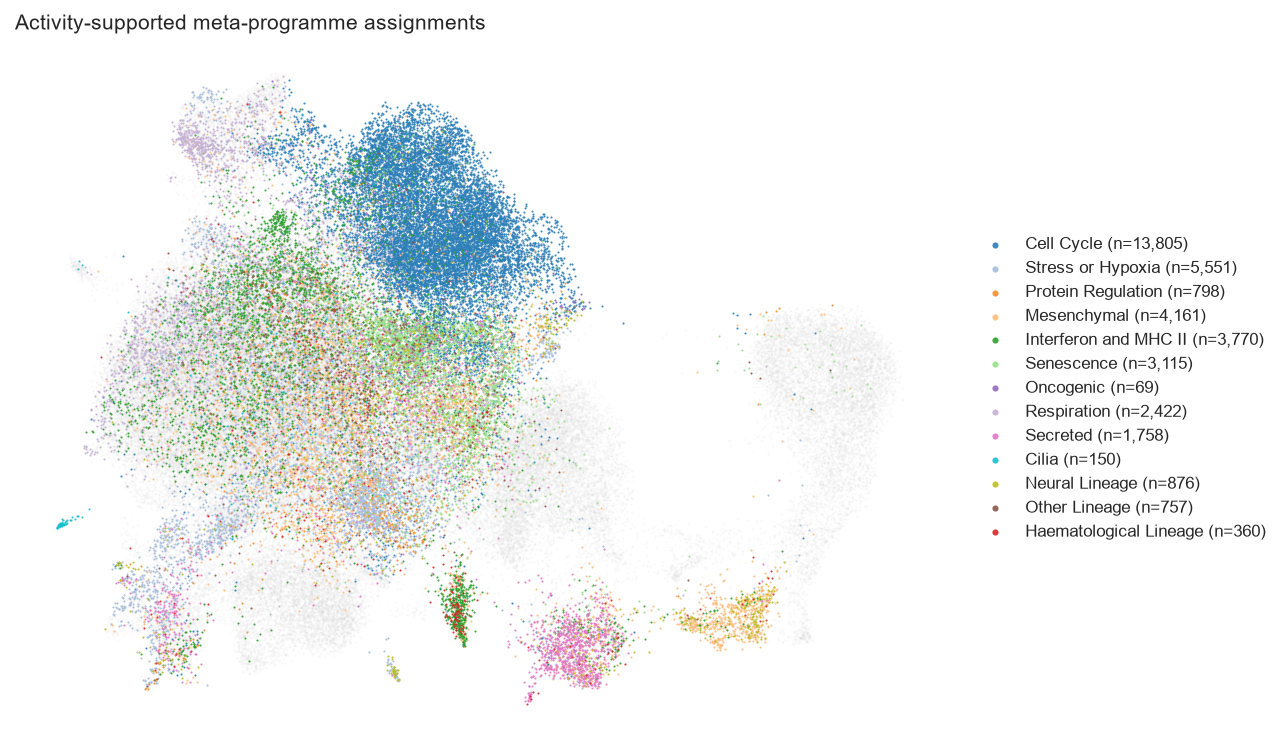

In [427]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    umap[:, 0],
    umap[:, 1],
    s=point_size,
    color="#D9D9D9",
    alpha=0.18,
    linewidths=0,
    rasterized=True,
)
for programme in candidate_hallmarks:
    mask = (plot_values == programme).to_numpy()
    ax.scatter(
        umap[mask, 0],
        umap[mask, 1],
        s=point_size,
        color=programme_palette[programme],
        alpha=0.9,
        linewidths=0,
        rasterized=True,
        label=f"{programme} (n={mask.sum():,})",
    )
ax.set_title("Activity-supported meta-programme assignments", loc="left")
ax.set_axis_off()
ax.legend(
    bbox_to_anchor=(1.02, 0.5),
    loc="center left",
    frameon=False,
    markerscale=3,
    fontsize=8,
)
save_umap_figure(fig, fig_dir / "meta_programme_assignments_umap", close=False, overwrite=False)
plt.show()


## Exploratory lineage scores

Continuous MP13/EMT, luminal-progenitor and mammary stem-cell-associated scores are additional exploratory endpoints. They do not change programme assignments. The Lim sets use the human-symbol curation of Lim et al. (2010), doi:10.1186/bcr2560; source membership and verified symbol mappings are frozen in `data/mammary_lineage_signatures.json`.

The primary continuous score is mean saved log-normalised expression. Technical libraries are averaged equally within donors. All six comparisons (three axes, each TN versus HER2+ and ER+) receive Holm correction. Fixed-control scores, at least 500 detected genes and CNV-high cells are separate sensitivities; every result is exported. These analyses are exploratory and were not preregistered.

The additional matrix uses actual epithelial clusters, with donor-paired cluster-versus-rest contrasts. Its depth adjustment is a within-library descriptive sensitivity. A signature score does not establish functional stemness, a lineage transition, or the number of progenitor cells.

In [428]:
lineage_signature_file = reference_dir / "mammary_lineage_signatures.json"


In [429]:
lineage_df_dir = df_dir / "lineage_axes"


In [430]:
lineage_fig_dir = fig_dir / "lineage_axes"


In [431]:
lineage_df_dir.mkdir(parents=True, exist_ok=True)


In [432]:
def lineage__matched_controls(template, bins, pool, seed, copies=5):
    """Choose unique controls across five expression-matched signature copies."""
    rng = np.random.default_rng(seed)
    selected = []
    for _ in range(copies):
        for target_bin, number in (
            bins.loc[template].value_counts().sort_index().items()
        ):
            remaining = pool[~pool.isin(selected)]
            same = remaining[bins.loc[remaining].eq(target_bin).to_numpy()]
            if len(same) < number:
                distance = (bins.loc[remaining] - target_bin).abs()
                if len(distance) < number:
                    raise ValueError(
                        "Insufficient unique expression-matched control genes"
                    )
                same = remaining[distance.le(distance.nsmallest(int(number)).iloc[-1])]
            selected.extend(rng.choice(same, size=int(number), replace=False).tolist())
    if len(set(selected)) != copies * len(template):
        raise ValueError("Control-gene cardinality mismatch")
    return selected


In [433]:
def lineage__mean(expression, positions):
    return np.asarray(expression[:, positions].mean(axis=1)).ravel()


In [434]:
lineage_axes = {
    "EMT_MP13": "EMT-associated (MP13)",
    "Luminal_progenitor": "Luminal-progenitor signature",
    "Mammary_stem_associated": "Mammary stem-cell-associated signature",
}


In [435]:
lineage_conditions = ["TN", "HER2+", "ER+"]


In [436]:
lineage_signature_names = {
    "Luminal_progenitor": "LIM_MAMMARY_LUMINAL_PROGENITOR_UP",
    "Mammary_stem_associated": "LIM_MAMMARY_STEM_CELL_UP",
}


In [437]:
lineage_signature_sha256 = (
    "e82ffe0c1bc402d77819934239129fe169bd11501856943bbf4815f4207094c2"
)


In [438]:
def lineage_stable_seed(label, seed=0):
    return int(hashlib.sha256(f"{seed}|{label}".encode()).hexdigest()[:8], 16)


In [439]:
lineage_metadata = (
    epi.obs.loc[
        scored_cells,
        [
            sample_key,
            donor_key,
            condition_key,
            cluster_key,
            "total_counts",
            "n_genes_by_counts",
            "tumour_derived_cnv_high",
        ],
    ]
    .copy()
    .rename(
        columns={
            sample_key: "sample",
            donor_key: "patient",
            condition_key: "condition",
            cluster_key: "epi_leiden",
        }
    )
)


In [440]:
axis_signature_file = lineage_signature_file


In [441]:
axis_required = {
    "sample",
    "patient",
    "condition",
    "total_counts",
    "n_genes_by_counts",
    "tumour_derived_cnv_high",
}


In [442]:
if axis_required.difference(lineage_metadata):
    raise ValueError(
        f"Missing metadata: {sorted(axis_required.difference(lineage_metadata))}"
    )


In [443]:
if not lineage_metadata.index.is_unique or not lineage_metadata.index.equals(
    mp_scores.index
):
    raise ValueError(
        "Continuous scores and metadata must have identical ordered cell IDs"
    )


In [444]:
if x_expression.shape != (len(lineage_metadata), len(gene_names)):
    raise ValueError("Expression shape differs from the supplied cells/features")


In [445]:
axis_genes = pd.Index(gene_names.astype(str))


In [446]:
if not axis_genes.is_unique or lineage_metadata[list(axis_required)].isna().any().any():
    raise ValueError("Unique features and complete analysis metadata are required")


In [447]:
if lineage_metadata.groupby("patient", observed=True).condition.nunique().max() != 1:
    raise ValueError(
        "Retain one condition per independent donor, using the main eligibility rule"
    )


In [448]:
if not set(lineage_metadata.condition.astype(str)).issubset(lineage_conditions):
    raise ValueError(
        "Only the main eligible tumour-derived population should be supplied"
    )


In [449]:
axis_signature_file = Path(axis_signature_file)


In [450]:
if (
    hashlib.sha256(axis_signature_file.read_bytes()).hexdigest()
    != lineage_signature_sha256
):
    raise ValueError("Frozen mammary-lineage signature checksum mismatch")


In [451]:
axis_source = json.loads(axis_signature_file.read_text())


In [452]:
axis_mp13 = [
    axis_name
    for axis_name in meta_programme_states
    if re.match("^MP13(?:\\s|$)", axis_name)
]


In [453]:
if len(axis_mp13) != 1 or axis_mp13[0] not in mp_scores:
    raise ValueError("Exactly one original MP13 score/signature is required")


In [454]:
axis_requested = {"EMT_MP13": list(meta_programme_states[axis_mp13[0]])}


In [455]:
axis_requested.update(
    {
        axis_axis: axis_source["sets"][axis_name]["genes"]
        for axis_axis, axis_name in lineage_signature_names.items()
    }
)


In [456]:
axis_positions = pd.Series(np.arange(len(axis_genes)), index=axis_genes)


In [457]:
axis_id_to_name = {}


In [458]:
if epi.var["gene_id"].astype(str) is not None:
    axis_ids = (
        pd.Index(epi.var["gene_id"].astype(str).astype(str)).str.split(".").str[0]
    )
    if len(axis_ids) != len(axis_genes) or not axis_ids.is_unique:
        raise ValueError(
            "Ordered unique feature IDs are required for symbol resolution"
        )
    axis_id_to_name = dict(zip(axis_ids, axis_genes))


In [459]:
axis_resolved_sets = {}


In [460]:
axis_resolutions = {}


In [461]:
for axis_axis, axis_original in axis_requested.items():
    axis_resolved_sets[axis_axis] = {}
    axis_resolutions[axis_axis] = []
    if gene_policy is not None:
        if epi.var["gene_id"].astype(str) is None:
            raise ValueError(
                "Original feature IDs are required by the reviewed gene policy"
            )
        axis_feature_var = pd.DataFrame(
            {"gene_id": np.asarray(epi.var["gene_id"].astype(str), str)},
            index=axis_genes,
        )
        axis__, axis_mapping = resolve_signature(
            axis_original, axis_feature_var, gene_policy
        )
        axis_resolved_sets[axis_axis] = dict(
            zip(
                axis_mapping.loc[axis_mapping.used, "source_gene"],
                axis_mapping.loc[axis_mapping.used, "feature_gene"],
            )
        )
        axis_resolutions[axis_axis] = [
            f"{axis_a}={axis_b}"
            for axis_a, axis_b in axis_resolved_sets[axis_axis].items()
            if axis_a != axis_b
        ]
        continue
    for axis_gene in dict.fromkeys(axis_original):
        axis_actual = axis_gene if axis_gene in axis_genes else None
        if axis_actual is None:
            axis_stable_id = (
                axis_source.get("symbol_resolution_by_ensembl", {})
                .get(axis_gene, {})
                .get("ensembl_gene_id")
            )
            axis_actual = axis_id_to_name.get(axis_stable_id)
            if axis_actual is not None:
                axis_resolutions[axis_axis].append(f"{axis_gene}={axis_actual}")
        if axis_actual is not None:
            axis_resolved_sets[axis_axis][axis_gene] = axis_actual
    if len(set(axis_resolved_sets[axis_axis].values())) != len(
        axis_resolved_sets[axis_axis]
    ):
        raise ValueError(
            f"Several signature genes resolve to one expression feature for {axis_axis}"
        )


In [462]:
axis_means = pd.Series(np.asarray(x_expression.mean(axis=0)).ravel(), index=axis_genes)


In [463]:
axis_bins = pd.qcut(
    axis_means.rank(method="first"), q=min(25, len(axis_genes)), labels=False
).astype(int)


In [464]:
if gene_policy is not None:
    axis_mp_background_exclusions = [
        set(resolve_signature(axis_g, axis_feature_var, gene_policy)[0])
        for axis_g in meta_programme_states.values()
    ]
else:
    axis_mp_background_exclusions = [
        set(axis_g) for axis_g in meta_programme_states.values()
    ]


In [465]:
axis_excluded = set().union(
    *axis_mp_background_exclusions,
    *(set(axis_g.values()) for axis_g in axis_resolved_sets.values()),
)


In [466]:
if gene_policy is not None:
    axis_pool = background_feature_pool(axis_feature_var, axis_excluded, gene_policy)
else:
    axis_pool = axis_genes[~axis_genes.isin(axis_excluded)]


In [467]:
axis_cells = lineage_metadata.copy()


In [468]:
axis_coverage = []


In [469]:
axis_control_rows = []


In [470]:
for axis_axis, axis_original in axis_requested.items():
    axis_original = list(dict.fromkeys(axis_original))
    axis_present = list(axis_resolved_sets[axis_axis].values())
    axis_missing = [
        axis_g
        for axis_g in axis_original
        if axis_g not in axis_resolved_sets[axis_axis]
    ]
    if not axis_original or len(axis_present) / len(axis_original) < 0.5:
        raise ValueError(f"Insufficient available genes for {axis_axis}")
    axis_cells[axis_axis + "__mean"] = lineage__mean(
        x_expression, axis_positions.loc[axis_present].to_numpy()
    )
    if axis_axis == "EMT_MP13":
        axis_cells[axis_axis + "__control"] = mp_scores[axis_mp13[0]].to_numpy(float)
        axis_controls = []
        axis_policy = "existing primary 41-programme fixed-control score"
    else:
        axis_controls = lineage__matched_controls(
            axis_present,
            axis_bins,
            axis_pool,
            lineage_stable_seed("lineage_controls::" + axis_axis, random_seed),
        )
        axis_cells[axis_axis + "__control"] = axis_cells[
            axis_axis + "__mean"
        ] - lineage__mean(x_expression, axis_positions.loc[axis_controls].to_numpy())
        axis_policy = "five controls per gene; 25 expression bins; original MPs and both Lim sets excluded from new control pool"
    axis_coverage.append(
        {
            "axis": axis_axis,
            "label": lineage_axes[axis_axis],
            "n_original": len(axis_original),
            "n_present": len(axis_present),
            "coverage": len(axis_present) / len(axis_original),
            "missing_genes": ";".join(axis_missing),
            "present_genes": ";".join(axis_present),
            "control_policy": axis_policy,
            "verified_symbol_resolutions": ";".join(axis_resolutions[axis_axis]),
        }
    )
    axis_control_rows.append(
        {
            "axis": axis_axis,
            "controls": ";".join(axis_controls),
            "n_controls": len(axis_controls),
            "policy": axis_policy,
        }
    )


In [471]:
axis_score_columns = [
    axis_axis + axis_suffix
    for axis_axis in lineage_axes
    for axis_suffix in ["__mean", "__control"]
]


In [472]:
if not np.isfinite(axis_cells[axis_score_columns].to_numpy(float)).all():
    raise ValueError("Non-finite continuous signature scores")


In [473]:
lineage_cells, lineage_coverage, lineage_controls = (
    axis_cells,
    pd.DataFrame(axis_coverage),
    pd.DataFrame(axis_control_rows),
)


In [474]:
display(
    lineage_coverage[
        ["label", "n_original", "n_present", "coverage", "verified_symbol_resolutions"]
    ]
)


,label,n_original,n_present,coverage,verified_symbol_resolutions
0,EMT-associated (MP13),50,50,1.0,PRKCDBP=CAVIN3;C15ORF48=C15orf48
1,Luminal-progenitor signature,58,58,1.0,
2,Mammary stem-cell-associated signature,478,478,1.0,POPDC1=BVES;ECRG4=C2orf40;PALM2AKAP2=PALM2-AKA...


In [475]:
def lineage_aggregate_donors(cells, columns, min_cells=100):
    """Average cells within a library, then give each donor's libraries equal weight."""
    if not cells.index.is_unique:
        raise ValueError("Duplicate cell IDs")
    if cells.groupby("patient", observed=True).condition.nunique().max() > 1:
        raise ValueError("A donor cannot supply two independent condition observations")
    mapping = cells[["sample", "patient", "condition"]].drop_duplicates()
    if mapping["sample"].duplicated().any():
        raise ValueError("A library has multiple donor/condition identities")
    keys = ["sample", "patient", "condition"]
    libraries = cells.groupby(keys, observed=True)[columns].mean()
    libraries["n_cells"] = cells.groupby(keys, observed=True).size()
    libraries = libraries[libraries.n_cells.ge(min_cells)].reset_index()
    if libraries.empty:
        return (
            libraries,
            pd.DataFrame(
                columns=["patient", "condition", *columns, "n_cells", "n_libraries"]
            ),
        )
    donors = libraries.groupby(["patient", "condition"], observed=True)[columns].mean()
    counts = libraries.groupby(["patient", "condition"], observed=True).agg(
        n_cells=("n_cells", "sum"), n_libraries=("sample", "nunique")
    )
    return (libraries, donors.join(counts).reset_index())


In [476]:
def lineage_exact_differences(left, right):
    """Enumerate all fixed-size donor-label permutations for several axes together."""
    left, right = (np.asarray(left, float), np.asarray(right, float))
    if left.ndim == 1:
        left, right = (left[:, None], right[:, None])
    if (
        min(len(left), len(right)) < 2
        or not np.isfinite(np.vstack([left, right])).all()
    ):
        raise ValueError("At least two finite observations per condition are required")
    values = np.vstack([left, right])
    n1, n2 = (len(left), len(right))
    delta = left.mean(axis=0) - right.mean(axis=0)
    total = values.sum(axis=0)
    extreme = np.zeros(values.shape[1], dtype=np.int64)
    n_permutations = 0
    combinations = itertools.combinations(range(n1 + n2), n1)
    while True:
        block = list(itertools.islice(combinations, 4096))
        if not block:
            break
        selected = np.asarray(block, dtype=int)
        sums = values[selected].sum(axis=1)
        differences = sums / n1 - (total - sums) / n2
        extreme += (np.abs(differences) >= np.abs(delta) - 1e-12).sum(axis=0)
        n_permutations += len(block)
    return (delta, extreme / n_permutations, n_permutations)


In [477]:
def lineage_donor_tests(donors, suffix="__mean", seed=0, bootstrap=10000):
    """Six exploratory contrasts: all three axes, TN versus HER2+ and ER+."""
    columns = [axis + suffix for axis in lineage_axes]
    rows = []
    left = donors.loc[donors.condition.eq("TN"), columns].to_numpy(float)
    for comparator in ["HER2+", "ER+"]:
        right = donors.loc[donors.condition.eq(comparator), columns].to_numpy(float)
        if min(len(left), len(right)) < 2:
            for axis in lineage_axes:
                rows.append(
                    {
                        "axis": axis,
                        "comparator": comparator,
                        "n_TN": len(left),
                        "n_comparator": len(right),
                        "difference": np.nan,
                        "ci_low": np.nan,
                        "ci_high": np.nan,
                        "p_exact": np.nan,
                        "n_permutations": 0,
                        "status": "insufficient_donors",
                    }
                )
            continue
        delta, p, n = lineage_exact_differences(left, right)
        rng = np.random.default_rng(
            lineage_stable_seed(
                "lineage_bootstrap::" + suffix + "::" + comparator, seed
            )
        )
        a = left[rng.integers(0, len(left), size=(bootstrap, len(left)))].mean(axis=1)
        b = right[rng.integers(0, len(right), size=(bootstrap, len(right)))].mean(
            axis=1
        )
        limits = np.quantile(a - b, [0.025, 0.975], axis=0)
        for j, axis in enumerate(lineage_axes):
            rows.append(
                {
                    "axis": axis,
                    "comparator": comparator,
                    "n_TN": len(left),
                    "n_comparator": len(right),
                    "difference": delta[j],
                    "ci_low": limits[0, j],
                    "ci_high": limits[1, j],
                    "p_exact": p[j],
                    "n_permutations": n,
                    "status": "tested",
                }
            )
    tests = pd.DataFrame(rows)
    tests["p_holm_six"] = multipletests(tests.p_exact.fillna(1), method="holm")[1]
    tests.loc[tests.status.ne("tested"), "p_holm_six"] = np.nan
    tests["score_kind"] = (
        "mean_log_normalised_expression"
        if suffix == "__mean"
        else "fixed_control_sensitivity"
    )
    tests["interpretation"] = (
        "exploratory; selected after inspection of earlier analyses"
    )
    return tests


In [478]:
def lineage_analyse_axes(cells, output_dir, min_cells=100, seed=0):
    """Export every defined population/score result; never select by P value."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    columns = [
        axis + suffix for axis in lineage_axes for suffix in ["__mean", "__control"]
    ]
    populations = {
        "primary_tumour_derived": np.ones(len(cells), dtype=bool),
        "min_500_genes_sensitivity": cells.n_genes_by_counts.ge(500).to_numpy(),
        "CNV_high_sensitivity": cells.tumour_derived_cnv_high.astype(bool).to_numpy(),
    }
    result = {}
    all_tests = []
    for population, mask in populations.items():
        libraries, donors = lineage_aggregate_donors(
            cells.loc[mask], columns, min_cells
        )
        libraries.to_csv(output_dir / f"{population}_library_scores.csv", index=False)
        donors.to_csv(output_dir / f"{population}_donor_scores.csv", index=False)
        for suffix in ["__mean", "__control"]:
            tests = lineage_donor_tests(
                donors, suffix, lineage_stable_seed(population, seed)
            )
            tests.insert(0, "population", population)
            tests.to_csv(output_dir / f"{population}{suffix}_tests.csv", index=False)
            all_tests.append(tests)
        result[population] = donors
    pd.concat(all_tests, ignore_index=True).to_csv(
        output_dir / "all_exploratory_tests.csv", index=False
    )
    return result


In [479]:
def lineage_write_manifest(output_dir, cells, coverage, signature_file, seed=0):
    """Make the exploratory status and unchanged main classification explicit."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    payload = {
        "analysis": "exploratory continuous mammary lineage axes",
        "n_cells": len(cells),
        "n_libraries": cells["sample"].nunique(),
        "n_donors": cells["patient"].nunique(),
        "donors_by_condition": cells.groupby("condition", observed=True)
        .patient.nunique()
        .to_dict(),
        "ordered_cell_ids_sha256": hashlib.sha256(
            "\n".join(cells.index.astype(str)).encode()
        ).hexdigest(),
        "signature_file_sha256": hashlib.sha256(
            Path(signature_file).read_bytes()
        ).hexdigest(),
        "primary_score": "mean saved log-normalised expression of available signature genes",
        "inference": "equal-weight technical-library means, then independent donors; exact two-sided label permutations",
        "multiplicity": "Holm over six contrasts: three axes times TN versus HER2+ and ER+; separate labelled sensitivity families",
        "random_seed": seed,
        "limitations": [
            "Hypotheses added after examining earlier analyses; exploratory, not preregistered",
            "MaSC-associated expression is not functional stemness, lineage tracing or evidence of an EMT transition",
            "Signature expression and assigned-class prevalence are different endpoints",
            "No changes to existing activity calls, cell selection or integration",
        ],
        "signature_coverage": coverage.to_dict("records"),
    }
    score_table = output_dir / "cell_scores.csv.gz"
    if score_table.exists():
        payload["cell_score_table_sha256"] = hashlib.sha256(
            score_table.read_bytes()
        ).hexdigest()
    (output_dir / "lineage_axes_manifest.json").write_text(
        json.dumps(payload, indent=2) + "\n"
    )
    return payload


In [480]:
lineage_cells.to_csv(
    lineage_df_dir / "cell_scores.csv.gz",
    index_label="cell_id",
    compression={"method": "gzip", "mtime": 0},
)


In [481]:
lineage_coverage.to_csv(lineage_df_dir / "signature_coverage.csv", index=False)


In [482]:
lineage_controls.to_csv(lineage_df_dir / "fixed_control_genes.csv", index=False)


In [483]:
lineage_results = lineage_analyse_axes(
    lineage_cells, lineage_df_dir, min_cells=min_cells_per_sample, seed=random_seed
)


In [484]:
lineage_manifest = lineage_write_manifest(
    lineage_df_dir,
    lineage_cells,
    lineage_coverage,
    lineage_signature_file,
    seed=random_seed,
)


In [485]:
lineage_primary_tests = pd.read_csv(
    lineage_df_dir / "primary_tumour_derived__mean_tests.csv"
)


In [486]:
display(lineage_primary_tests)


,population,axis,comparator,n_TN,n_comparator,difference,ci_low,ci_high,p_exact,n_permutations,status,p_holm_six,score_kind,interpretation
0,primary_tumour_derived,EMT_MP13,HER2+,6,6,0.131790,0.047102,0.202400,0.017316,924,tested,0.035744,mean_log_normalised_expression,exploratory; selected after inspection of earl...
1,primary_tumour_derived,Luminal_progenitor,HER2+,6,6,0.044573,0.017311,0.072282,0.017316,924,tested,0.035744,mean_log_normalised_expression,exploratory; selected after inspection of earl...
2,primary_tumour_derived,Mammary_stem_associated,HER2+,6,6,0.050555,0.025922,0.080186,0.006494,924,tested,0.025974,mean_log_normalised_expression,exploratory; selected after inspection of earl...
3,primary_tumour_derived,EMT_MP13,ER+,6,16,0.123908,0.030410,0.202396,0.011915,74613,tested,0.035744,mean_log_normalised_expression,exploratory; selected after inspection of earl...
4,primary_tumour_derived,Luminal_progenitor,ER+,6,16,0.054682,0.029168,0.080839,0.000201,74613,tested,0.001206,mean_log_normalised_expression,exploratory; selected after inspection of earl...
5,primary_tumour_derived,Mammary_stem_associated,ER+,6,16,0.050058,0.023447,0.080102,0.000831,74613,tested,0.004155,mean_log_normalised_expression,exploratory; selected after inspection of earl...


In [487]:
lineage_palette = {"TN": "#976391", "HER2+": "#2CA02C", "ER+": "#F46036"}


In [488]:
def lineage_plot_donors(donors, tests):
    """Keep all donors visible and show both requested corrected contrasts."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), layout="constrained")
    for ax, (axis, label) in zip(axes, lineage_axes.items()):
        ticks = []
        for j, condition in enumerate(lineage_conditions):
            block = donors.loc[donors.condition.eq(condition)].sort_values("patient")
            values = block[axis + "__mean"].to_numpy(float)
            jitter = (
                np.linspace(-0.14, 0.14, len(values))
                if len(values) > 1
                else np.zeros(len(values))
            )
            ax.scatter(
                j + jitter,
                values,
                s=36,
                color=lineage_palette[condition],
                edgecolor="white",
                linewidth=0.5,
                zorder=3,
            )
            if len(values):
                ax.hlines(
                    values.mean(), j - 0.25, j + 0.25, color="#222222", linewidth=1.5
                )
            ticks.append(f"{condition}\n(n={len(values)})")
        subset = tests[tests.axis.eq(axis)]
        text = []
        for comparator in ["HER2+", "ER+"]:
            row = subset.loc[subset.comparator.eq(comparator)].iloc[0]
            value = (
                f"{row.p_holm_six:.3g}" if pd.notna(row.p_holm_six) else "not tested"
            )
            text.append(f"TN vs {comparator}: Holm P = {value}")
        ax.text(
            0.02, 1.02, "\n".join(text), transform=ax.transAxes, fontsize=8, va="bottom"
        )
        ax.set_xticks(range(3), ticks, fontsize=10)
        ax.tick_params(axis="y", labelsize=9)
        ax.set_title(label, fontsize=11, pad=38, loc="left")
        ax.set_ylabel("Mean log-normalised signature expression", fontsize=10)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", color="#E5E7EB", linewidth=0.6)
        ax.grid(axis="x", visible=False)
    return fig


In [489]:
lineage_fig_dir.mkdir(parents=True, exist_ok=True)

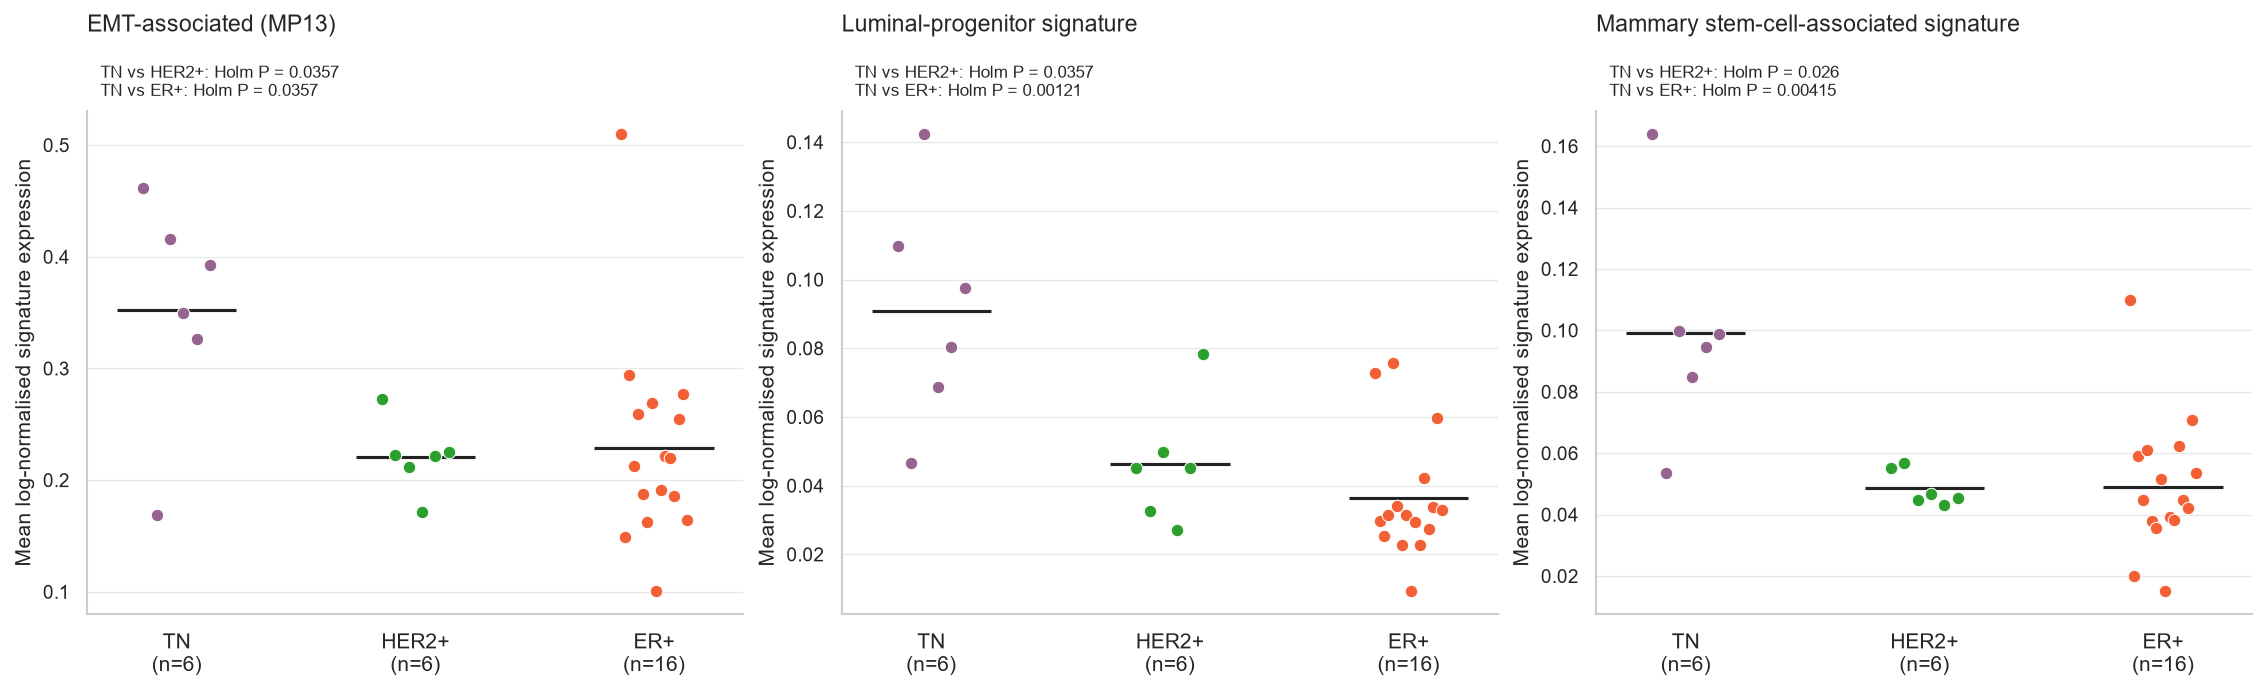

In [490]:
fig = lineage_plot_donors(
    lineage_results["primary_tumour_derived"], lineage_primary_tests
)
save_figure(fig, lineage_fig_dir / "lineage_signature_donor_scores", close=False, overwrite=False)
plt.show()


In [491]:
def lineage_cluster_associations(
    mp_scores, metadata, cluster_key="epi_leiden", min_cells=10, min_donors=3
):
    """Donor-paired cluster-versus-rest contrasts, with a library depth sensitivity.

    Rows are actual epithelial clusters, not groups defined from their leading MP.
    Linear depth removal is confined to this descriptive within-library contrast;
    it is not used to force donor-level signature differences to zero.
    """
    required = {"sample", "patient", "condition", "total_counts", cluster_key}
    if required.difference(metadata) or not metadata.index.equals(mp_scores.index):
        raise ValueError("Ordered cluster metadata do not match the MP score matrix")
    programmes = list(mp_scores)
    values = mp_scores.to_numpy(float)
    records = []
    for sample, positions in metadata.groupby("sample", observed=True).indices.items():
        block = metadata.iloc[positions]
        if block.patient.nunique() != 1 or block.condition.nunique() != 1:
            raise ValueError("Library has inconsistent donor metadata")
        y = values[positions]
        depth = np.log1p(block.total_counts.to_numpy(float))
        dx = depth - depth.mean()
        denominator = np.dot(dx, dx)
        slopes = dx @ y / denominator if denominator > 0 else np.zeros(y.shape[1])
        adjusted = y - dx[:, None] * slopes
        clusters = block[cluster_key].astype(str).to_numpy()
        for cluster in pd.unique(clusters):
            inside = clusters == cluster
            if min(inside.sum(), (~inside).sum()) < min_cells:
                continue
            for score_kind, matrix in [("unadjusted", y), ("depth_adjusted", adjusted)]:
                difference = matrix[inside].mean(axis=0) - matrix[~inside].mean(axis=0)
                for mp, delta in zip(programmes, difference):
                    records.append(
                        {
                            "sample": sample,
                            "patient": str(block.patient.iloc[0]),
                            "cluster": cluster,
                            "mp": mp,
                            "score_kind": score_kind,
                            "delta": delta,
                        }
                    )
    libraries = pd.DataFrame(records)
    if libraries.empty:
        raise ValueError(
            "No cluster-versus-rest contrast meets the cell-count requirement"
        )
    donors = (
        libraries.groupby(["patient", "cluster", "mp", "score_kind"], observed=True)
        .delta.mean()
        .reset_index()
    )
    summary = (
        donors.groupby(["cluster", "mp", "score_kind"], observed=True)
        .agg(
            median_delta=("delta", "median"),
            fraction_donors_positive=("delta", lambda x: (x > 0).mean()),
            n_donors=("patient", "nunique"),
        )
        .reset_index()
    )
    summary["eligible"] = summary.n_donors.ge(min_donors)
    return (libraries, donors, summary)


In [492]:
lineage_cluster_libraries, lineage_cluster_donors, lineage_cluster_summary = (
    lineage_cluster_associations(
        mp_scores, lineage_metadata, min_cells=10, min_donors=min_units_per_cluster
    )
)


In [493]:
lineage_cluster_libraries.to_csv(
    lineage_df_dir / "cluster_contrasts_by_library.csv", index=False
)


In [494]:
lineage_cluster_donors.to_csv(
    lineage_df_dir / "cluster_contrasts_by_donor.csv", index=False
)


In [495]:
lineage_cluster_summary.to_csv(
    lineage_df_dir / "cluster_association_summary.csv", index=False
)


## Save

In [496]:
assert epi.obs.loc[scored_cells, "MP_programme_call"].notna().all()


In [497]:
assert epi.obs.loc[scored_cells, "MP_Mesenchymal_score"].notna().all()


In [498]:
assert epi.obs.loc[scored_cells, "three_ca_style_parent_call"].notna().all()


In [499]:
assert set(programme_call.unique()).issubset(set(call_order))


In [500]:
epi.uns["meta_programme_analysis"] = {
    "signature_source": signature_source,
    "signature_source_url": signature_source_url,
    "signature_sha256": signature_sha256,
    "primary_method": "adapted matched-null projection; not the original 3CA assignment algorithm",
    "score": "mean log-normalised signature expression minus fixed matched controls",
    "activity": f"empirical expression-matched null p-values; Holm-adjusted within cell at familywise alpha {activity_familywise_alpha:.2f}; at least {min_detected_signature_fraction:.2f} of genes detected",
    "programme_call": f"best active class; multiple active classes require margin >= {top2_margin:.2f}",
    "condition_unit": "donor by condition; technical samples averaged within unit",
    "condition_unit_independence": "one retained condition per donor after eligibility filtering",
    "cluster_summary": "donor-centred relative enrichment; not a cell identity",
    "min_cells_per_sample": int(min_cells_per_sample),
    "min_signature_coverage": float(min_signature_coverage),
    "n_expression_bins": int(n_expression_bins),
    "n_controls_per_gene": int(n_controls_per_gene),
    "n_null_signatures": int(n_null_signatures),
    "three_ca_style_sensitivity": {
        "implementation": "Python reimplementation; not scalop output",
        "method_url": three_ca_method_url,
        "scoring_url": three_ca_scoring_url,
        "transform": "log2(CPM / 10 + 1)",
        "expression_bins": int(three_ca_expression_bins),
        "controls_per_gene": int(three_ca_controls_per_gene),
        "min_genes": int(three_ca_min_genes),
        "min_score": float(three_ca_min_score),
        "min_within_sample_frequency": float(three_ca_min_frequency),
    },
    "seed": int(random_seed),
}


Class-ranking sensitivity. An alternative ranks the all-member class score with its matching scale, retaining the same activity gate and ambiguity margin. This check does not replace the primary calls. Global profile tests and individual programme tests are reported separately; the latter use 99,999 permutations to examine Monte Carlo sensitivity near the significance threshold.

In [501]:
def check_condition_tests(profiles, categories, seed=0, permutations=99999):
    labels = profiles.condition.astype(str).to_numpy()
    levels = np.unique(labels)
    rows = []
    for category in categories:
        digest = hashlib.sha256(
            f"{seed}|kruskal::primary::{category}".encode()
        ).hexdigest()
        rng = np.random.default_rng(int(digest[:8], 16))
        shuffled = np.stack([rng.permutation(labels) for _ in range(permutations)])
        values = profiles[category].to_numpy(float)
        if np.allclose(values, values[0]):
            rows.append({"programme": category, "p_permutation": 1.0})
            continue
        ranks = stats.rankdata(values)
        _, counts = np.unique(values, return_counts=True)
        n = len(values)
        tie = 1 - np.sum(counts**3 - counts) / (n**3 - n)

        def statistic(assignments):
            term = sum(
                (
                    ((assignments == level) @ ranks) ** 2 / (labels == level).sum()
                    for level in levels
                )
            )
            return (12 * term / (n * (n + 1)) - 3 * (n + 1)) / tie

        observed = statistic(labels[None, :])[0]
        null = statistic(shuffled)
        rows.append(
            {
                "programme": category,
                "p_permutation": (1 + (null >= observed - 1e-12).sum())
                / (permutations + 1),
            }
        )
    result = pd.DataFrame(rows)
    result["p_holm"] = multipletests(result.p_permutation, method="holm")[1]
    result["n_permutations"] = permutations
    result["monte_carlo_se_unadjusted"] = np.sqrt(
        result.p_permutation * (1 - result.p_permutation) / (permutations + 1)
    )
    return result


In [502]:
def check_donor_profiles(obs, calls, categories):
    frame = obs.loc[
        calls.index, ["sample", "patient", "condition", "analysis_unit"]
    ].copy()
    frame["call"] = calls.astype(str)
    counts = frame.groupby("sample", observed=True).size()
    frame = frame[frame["sample"].isin(counts[counts >= 100].index)]
    sample = pd.crosstab(
        [frame["sample"], frame.analysis_unit, frame.condition],
        frame.call,
        normalize="index",
    )
    sample = sample.reindex(columns=categories, fill_value=0).reset_index()
    profiles = (
        sample.groupby(["analysis_unit", "condition"], observed=True)[categories]
        .mean()
        .reset_index()
    )
    if not np.allclose(profiles[categories].sum(axis=1), 1):
        raise ValueError("Incomplete programme composition.")
    return profiles


In [503]:
def check_profile_test(profiles, categories, seed=0, permutations=9999):
    """Permutation of independent donor labels on Hellinger profiles."""
    values = np.sqrt(profiles[categories].to_numpy(float))
    labels = profiles["condition"].astype(str).to_numpy()
    levels = np.unique(labels)
    if len(levels) < 2 or any(((labels == level).sum() < 2 for level in levels)):
        return {"n_units": len(labels), "r_squared": np.nan, "p_permutation": np.nan}
    total = float(np.sum((values - values.mean(axis=0)) ** 2))

    def between(assignments):
        result = np.zeros(len(assignments))
        for level in levels:
            membership = assignments == level
            sums = membership.astype(float) @ values
            result += np.sum(sums * sums, axis=1) / membership.sum(axis=1)
        return result - len(values) * np.sum(values.mean(axis=0) ** 2)

    observed = between(labels[None, :])[0]
    rng = np.random.default_rng(seed)
    shuffled = np.stack([rng.permutation(labels) for _ in range(permutations)])
    null = between(shuffled)
    return {
        "n_units": len(labels),
        "r_squared": observed / total,
        "p_permutation": (1 + (null >= observed - 1e-12).sum()) / (permutations + 1),
    }


In [504]:
repository = notebook_dir


In [505]:
check_dir = run_dir / "publication_checks"


In [506]:
check_dir.mkdir(parents=True, exist_ok=True)


In [507]:
ranking_check_scores = pd.read_csv(
    df_dir / "meta_programme_class_scores.csv", index_col=0
)


In [508]:
ranking_check_activity = pd.read_csv(
    df_dir / "meta_programme_mp_activity_calls.csv", index_col=0
)


In [509]:
if (
    not ranking_check_scores.index.equals(ranking_check_activity.index)
    or ranking_check_activity.isna().any().any()
):
    raise ValueError("Programme score/activity rows do not align.")


In [510]:
ranking_check_groups = {
    "Cell Cycle": range(1, 5),
    "Stress or Hypoxia": range(5, 8),
    "Protein Regulation": range(8, 12),
    "Mesenchymal": range(12, 17),
    "Interferon and MHC II": range(17, 19),
    "Senescence": [19],
    "Oncogenic": [20],
    "Respiration": [21],
    "Secreted": [22, 23],
    "Cilia": [24],
    "Neural Lineage": range(25, 30),
    "Other Lineage": range(30, 33),
    "Haematological Lineage": range(33, 38),
}


In [511]:
ranking_check_ids = ranking_check_activity.columns.str.extract(
    "^(MP\\d+)", expand=False
)


In [512]:
ranking_check_mask = pd.DataFrame(
    {
        ranking_check_category: ranking_check_activity.loc[
            :,
            ranking_check_ids.isin(
                [f"MP{ranking_check_x}" for ranking_check_x in ranking_check_numbers]
            ),
        ].any(axis=1)
        for ranking_check_category, ranking_check_numbers in ranking_check_groups.items()
    },
    index=ranking_check_scores.index,
)


In [513]:
ranking_check_ranked = ranking_check_scores.where(ranking_check_mask, -np.inf)


In [514]:
ranking_check_n_active = ranking_check_mask.sum(axis=1)


In [515]:
ranking_check_ordered = np.sort(ranking_check_ranked.to_numpy(float), axis=1)


In [516]:
ranking_check_margin = np.full(len(ranking_check_scores), np.inf)


In [517]:
ranking_check_multiple = ranking_check_n_active.ge(2).to_numpy()


In [518]:
ranking_check_margin[ranking_check_multiple] = (
    ranking_check_ordered[ranking_check_multiple, -1]
    - ranking_check_ordered[ranking_check_multiple, -2]
)


In [519]:
ranking_check_alternative = ranking_check_ranked.idxmax(axis=1).where(
    ranking_check_n_active.gt(0), "low_activity"
)


In [520]:
ranking_check_alternative = ranking_check_alternative.where(
    ~(ranking_check_n_active.gt(0) & (ranking_check_margin < 0.25)),
    "mixed_active_but_ambiguous",
)


In [521]:
ranking_check_primary = epi.obs.loc[
    ranking_check_scores.index, "MP_programme_call"
].astype(str)


In [522]:
ranking_check_alternative = ranking_check_alternative.mask(
    ranking_check_primary.eq("unassigned_active"), "unassigned_active"
)


In [523]:
ranking_check_categories = list(ranking_check_scores) + [
    "low_activity",
    "mixed_active_but_ambiguous",
    "unassigned_active",
]


In [524]:
pd.crosstab(
    ranking_check_primary.rename("primary"),
    ranking_check_alternative.rename("all_member_ranking"),
).to_csv(check_dir / "class_ranking_confusion.csv")


In [525]:
ranking_check_counts = pd.concat(
    [
        ranking_check_primary.value_counts().rename("primary"),
        ranking_check_alternative.value_counts().rename("all_member_ranking"),
    ],
    axis=1,
).fillna(0)


In [526]:
ranking_check_counts.to_csv(check_dir / "class_ranking_assignment_counts.csv")


In [527]:
pd.DataFrame(
    {"primary": ranking_check_primary, "all_member_ranking": ranking_check_alternative}
).to_csv(check_dir / "class_ranking_cell_calls.csv")


In [528]:
ranking_check_summaries, ranking_check_tests = ([], [])


In [529]:
for ranking_check_name, ranking_check_calls in (
    ("primary", ranking_check_primary),
    ("all_member_ranking", ranking_check_alternative),
):
    ranking_check_profiles = check_donor_profiles(
        epi.obs, ranking_check_calls, ranking_check_categories
    )
    ranking_check_profiles.to_csv(
        check_dir / f"class_ranking_donor_profiles_{ranking_check_name}.csv",
        index=False,
    )
    ranking_check_summaries.append(
        {
            "method": ranking_check_name,
            **check_profile_test(ranking_check_profiles, ranking_check_categories),
        }
    )
    ranking_check_test = check_condition_tests(
        ranking_check_profiles, list(ranking_check_scores)
    )
    ranking_check_test["method"] = ranking_check_name
    ranking_check_tests.append(ranking_check_test)


In [530]:
ranking_check_summary = pd.DataFrame(ranking_check_summaries)


In [531]:
ranking_check_summary["cell_assignment_agreement"] = float(
    ranking_check_primary.eq(ranking_check_alternative).mean()
)


In [532]:
ranking_check_any_activity = ranking_check_primary.ne("low_activity")


In [533]:
ranking_check_both_biological = ranking_check_primary.isin(
    ranking_check_scores.columns
) & ranking_check_alternative.isin(ranking_check_scores.columns)


In [534]:
ranking_check_summary["agreement_among_activity_supported"] = float(
    ranking_check_primary[ranking_check_any_activity]
    .eq(ranking_check_alternative[ranking_check_any_activity])
    .mean()
)


In [535]:
ranking_check_summary["agreement_among_both_biologically_assigned"] = float(
    ranking_check_primary[ranking_check_both_biological]
    .eq(ranking_check_alternative[ranking_check_both_biological])
    .mean()
)


In [536]:
ranking_check_summary.to_csv(
    check_dir / "class_ranking_global_sensitivity.csv", index=False
)


In [537]:
pd.concat(ranking_check_tests).to_csv(
    check_dir / "class_ranking_condition_tests.csv", index=False
)


In [538]:
ranking_global, ranking_counts = (ranking_check_summary, ranking_check_counts)


In [539]:
display(ranking_global)


,method,n_units,r_squared,p_permutation,cell_assignment_agreement,agreement_among_activity_supported,agreement_among_both_biologically_assigned
0,primary,28,0.171916,0.0112,0.93839,0.850343,0.904553
1,all_member_ranking,28,0.173137,0.0098,0.93839,0.850343,0.904553


In [540]:
display(ranking_counts)


,primary,all_member_ranking
low_activity,57047,57047
Cell Cycle,13805,12637
Stress or Hypoxia,5551,5202
Mesenchymal,4161,3812
Interferon and MHC II,3770,4317
Senescence,3115,5551
Respiration,2422,2611
Secreted,1758,1567
mixed_active_but_ambiguous,1354,1543
unassigned_active,972,972


In [541]:
out_path = save_dir / "epithelial_meta_programmes.h5ad"


In [542]:
tmp_path = out_path.with_suffix(".h5ad.tmp")


In [543]:
def stamp_gene_policy(adata, policy, stage, cell_cycle_scored=None):
    previous = dict(adata.uns.get("gene_policy", {}))
    previous.update(
        {"version": policy["version"], "sha256": policy["sha256"], "stage": stage}
    )
    if cell_cycle_scored is not None:
        previous["cell_cycle_scored"] = bool(cell_cycle_scored)
    adata.uns["gene_policy"] = previous


In [544]:
stamp_gene_policy(epi, gene_policy, "meta_programmes")


In [545]:
for layer in epi.layers:
    if not sp.issparse(epi.layers[layer]):
        epi.layers[layer] = sp.csr_matrix(epi.layers[layer])


In [546]:
if out_path.exists():
    raise FileExistsError("Analysis output already exists; choose a new run_dir for a fresh analysis.")


In [547]:
epi.write_h5ad(tmp_path, compression="gzip")


In [548]:
os.replace(tmp_path, out_path)


In [549]:
check = sc.read_h5ad(out_path, backed="r")


In [550]:
assert check.shape == epi.shape


In [551]:
del check


In [552]:
display(
    pd.DataFrame(
        {"saved": [out_path.name], "cells": [epi.n_obs], "genes": [epi.n_vars]}
    )
)


,saved,cells,genes
0,epithelial_meta_programmes.h5ad,123382,27292


In [553]:
session_info.show()


D:\Conda\envs\cap-rerun\Lib\site-packages\session_info\main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  mod_version = _find_version(mod.__version__)
D:\Conda\envs\cap-rerun\Lib\site-packages\session_info\main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  mod_version = _find_version(mod.__version__)
